# Ames Housing Price Prediction Project

**Dataset:** Ames Housing (`train.csv`, 1460 rows) | **Target:** `SalePrice`

---

## Table of Contents
- **Part A:** 1. Dataset Understanding | 2. EDA | 3. Data Analysis & Insights
- **Part B:** 4. Data Preprocessing | 5. Pipelines & ColumnTransformer
- **Part C:** 6. Model Development | 7. Hyperparameter Tuning | 8. Evaluation & Comparison | 9. Feature Importance | 10. Final Model Selection
- **Final:** 11. Reproducibility & Conclusions

## ⚙️ Setup
*(imports, `random_state` constant, plotting style, data loading cell that works on both local and Colab)*

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
#regression
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from sklearn.base import clone
RANDOM_STATE = 42


# PART A: Data Understanding, EDA & Insights

## 1. Dataset Understanding

### 1.1 Load and inspect the data
- [ ] Load the dataset
- [ ] Show head / tail / sample

In [3]:
df = pd.read_csv('train.csv')

none_cols = ['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
             'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
             'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']
df[none_cols] = df[none_cols].fillna('None')

df['MSSubClass'] = df['MSSubClass'].astype(str)

print("Shape:", df.shape)
display(df.head())
display(df.tail())
display(df.sample(3, random_state=RANDOM_STATE))

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,12,2008,WD,Normal,250000


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,None,Reg,Lvl,AllPub,...,0,None,MnPrv,None,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,None,Reg,Lvl,AllPub,...,0,None,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,None,Reg,Lvl,AllPub,...,0,None,None,None,0,6,2008,WD,Normal,147500


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
892,893,20,RL,70.0,8414,Pave,None,Reg,Lvl,AllPub,...,0,None,MnPrv,None,0,2,2006,WD,Normal,154500
1105,1106,60,RL,98.0,12256,Pave,None,IR1,Lvl,AllPub,...,0,None,None,None,0,4,2010,WD,Normal,325000
413,414,30,RM,56.0,8960,Pave,Grvl,Reg,Lvl,AllPub,...,0,None,None,None,0,3,2010,WD,Normal,115000


### 1.2 Basic information
- [ ] Shape
- [ ] Data types
- [ ] Number of duplicates
- [ ] Missing values (count and %)

In [4]:
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDuplicate rows (excluding Id):", df.drop(columns='Id').duplicated().sum())

missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})
display(missing[missing["Missing Count"] > 0].sort_values("Missing Count", ascending=False))



Data types:


,dtype
Id,int64
MSSubClass,object
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object



Duplicate rows (excluding Id): 0


,Missing Count,Missing %
LotFrontage,259,17.74
GarageYrBlt,81,5.55
MasVnrArea,8,0.55
Electrical,1,0.07


### 1.3 Target variable and main features
- [ ] Identify target (`SalePrice`)
- [ ] Brief description of the most important variables

In [5]:
target = "SalePrice"

print("Target:", target)
print("\nTarget statistics:")
display(df[target].describe())

# Top 10 numerical features most correlated with the target
top_corr = (df.select_dtypes(include='number')
              .drop(columns=['Id'])
              .corr()[target]
              .drop(target)
              .sort_values(key=abs, ascending=False)
              .head(10))
print("\nTop 10 features correlated with SalePrice:")
display(top_corr.round(2))

important_features = top_corr.index.tolist()
display(df[important_features + [target]].head())

Target: SalePrice

Target statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


Top 10 features correlated with SalePrice:


OverallQual     0.79
GrLivArea       0.71
GarageCars      0.64
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
FullBath        0.56
TotRmsAbvGrd    0.53
YearBuilt       0.52
YearRemodAdd    0.51
Name: SalePrice, dtype: float64

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd,SalePrice
0,7,1710,2,548,856,856,2,8,2003,2003,208500
1,6,1262,2,460,1262,1262,2,6,1976,1976,181500
2,7,1786,2,608,920,920,2,6,2001,2002,223500
3,7,1717,3,642,756,961,1,7,1915,1970,140000
4,8,2198,3,836,1145,1145,2,9,2000,2000,250000


**Target:** `SalePrice` is the sale price in USD (continuous, so this is a regression problem).

**Most important variables:**
- **OverallQual** (corr 0.79): overall material and finish quality, rated 1 (very poor) to 10 (very excellent). It is the strongest single predictor.
- **GrLivArea** (corr 0.71): above-ground living area in square feet. Larger homes cost more.
- **GarageCars** (corr 0.64): garage capacity in number of cars.
- **TotalBsmtSF** (corr 0.61): total basement area in square feet (0 = no basement).


### 1.4 Feature type classification
- [ ] Numerical features
- [ ] Nominal categorical features
- [ ] Ordinal categorical features (with the order of each one)
- [ ] Columns where `NA` means 'None' (no basement / garage / pool...) vs truly missing

In [6]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
#ignore the id and target columns
num_cols.remove('Id')
num_cols.remove('SalePrice')

# Extract Categorical Columns (Including MSSubClass)
cat_cols = df.select_dtypes(exclude='number').columns.tolist()

#ordinal mapping for ordinal categorical columns
qual = ['None','Po','Fa','TA','Gd','Ex']
ordinal_mapping = {
'ExterQual':qual[1:],'ExterCond':qual[1:],'HeatingQC':qual[1:],'KitchenQual':qual[1:],
'BsmtQual':qual,'BsmtCond':qual,'FireplaceQu':qual,
'GarageQual':qual,'GarageCond':qual,'PoolQC':qual,
'BsmtExposure':['None','No','Mn','Av','Gd'],
'BsmtFinType1':['None','Unf','LwQ','Rec','BLQ','ALQ','GLQ'],
'BsmtFinType2':['None','Unf','LwQ','Rec','BLQ','ALQ','GLQ'],
'GarageFinish':['None','Unf','RFn','Fin'],
'Functional':['Sal','Sev','Maj2','Maj1','Mod','Min2','Min1','Typ'],
'LotShape':['IR3','IR2','IR1','Reg'],'LandSlope':['Sev','Mod','Gtl'],
'PavedDrive':['N','P','Y']}
ordinal_cols = list(ordinal_mapping.keys())
nominal_cols = [col for col in cat_cols if col not in ordinal_cols]
print(f"Numerical Features ({len(num_cols)}): {num_cols}")
print(f"Ordinal Features ({len(ordinal_cols)}): {ordinal_cols}")
print(f"Nominal Features ({len(nominal_cols)}): {nominal_cols}")
#fill missing values for categorical columns with 'None' for specific columns
none_cols = ['Alley','MasVnrType','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1',
 'BsmtFinType2','FireplaceQu','GarageType','GarageFinish','GarageQual',
 'GarageCond','PoolQC','Fence','MiscFeature']
df[none_cols] = df[none_cols].fillna('None')


Numerical Features (35): ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']
Ordinal Features (18): ['ExterQual', 'ExterCond', 'HeatingQC', 'KitchenQual', 'BsmtQual', 'BsmtCond', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'GarageFinish', 'Functional', 'LotShape', 'LandSlope', 'PavedDrive']
Nominal Features (26): ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'Utilities', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1s

#### 📝 Section Summary
The Ames Housing training set has 1,460 houses and 81 columns, with `SalePrice` as the target (mean ≈ $180.9K, median $163K, right-skewed). There are no duplicate rows. After converting the "NA = feature absent" values to a real `None` category, only 4 columns are truly missing (`LotFrontage`, `GarageYrBlt`, `MasVnrArea`, `Electrical`). Features were split into 35 numerical, 26 nominal and 18 ordinal (with explicit orders); `MSSubClass` was treated as categorical because it is a code. `OverallQual` (0.79) and `GrLivArea` (0.71) are the strongest correlates of price.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Descriptive statistics
- [ ] Numerical summary
- [ ] Categorical summary

In [7]:
print("Numerical descriptive statistics:")
display(df.describe().T)

print("\nCategorical descriptive statistics:")
display(df.describe(include="object").T)


Numerical descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0



Categorical descriptive statistics:


,count,unique,top,freq
MSSubClass,1460,15,20,536
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,1460,3,None,1369
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225


### 2.2 Distribution of SalePrice
- [ ] Histogram + skewness
- [ ] Effect of log transform

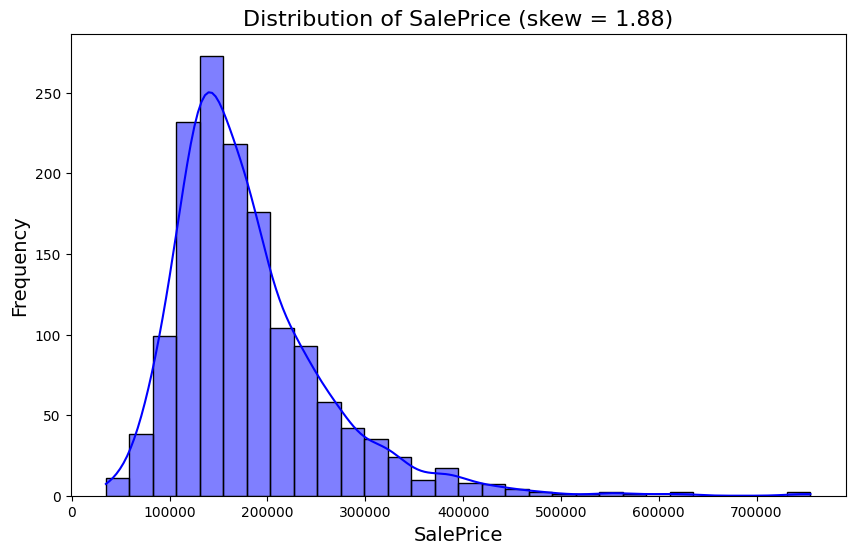

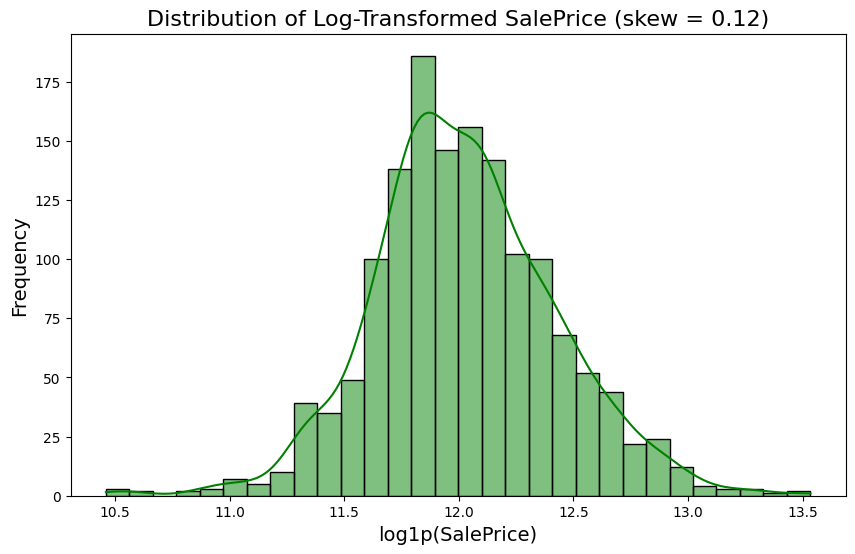

In [8]:
## Visualize the distribution of the target variable
plt.figure(figsize=(10, 6))
sns.histplot(df['SalePrice'], kde=True, bins=30, color='blue')
plt.title(f"Distribution of SalePrice (skew = {df['SalePrice'].skew():.2f})", fontsize=16)
plt.xlabel('SalePrice', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.show()

log_price = np.log1p(df['SalePrice'])
plt.figure(figsize=(10, 6))
sns.histplot(log_price, kde=True, bins=30, color='green')
plt.title(f"Distribution of Log-Transformed SalePrice (skew = {log_price.skew():.2f})", fontsize=16)
plt.xlabel('log1p(SalePrice)', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.show()

### 2.3 Distribution of important numerical features
- [ ] Histograms
- [ ] Skewness values

Skewness of the important features:


OverallQual     0.22
GrLivArea       1.37
GarageCars     -0.34
GarageArea      0.18
TotalBsmtSF     1.52
1stFlrSF        1.38
FullBath        0.04
TotRmsAbvGrd    0.68
YearBuilt      -0.61
YearRemodAdd   -0.50
dtype: float64


Highly skewed numerical features (|skew| > 0.75):


MiscVal          24.48
PoolArea         14.83
LotArea          12.21
3SsnPorch        10.30
LowQualFinSF      9.01
KitchenAbvGr      4.49
BsmtFinSF2        4.26
ScreenPorch       4.12
BsmtHalfBath      4.10
EnclosedPorch     3.09
MasVnrArea        2.67
OpenPorchSF       2.36
LotFrontage       2.16
BsmtFinSF1        1.69
WoodDeckSF        1.54
TotalBsmtSF       1.52
1stFlrSF          1.38
GrLivArea         1.37
BsmtUnfSF         0.92
2ndFlrSF          0.81
dtype: float64

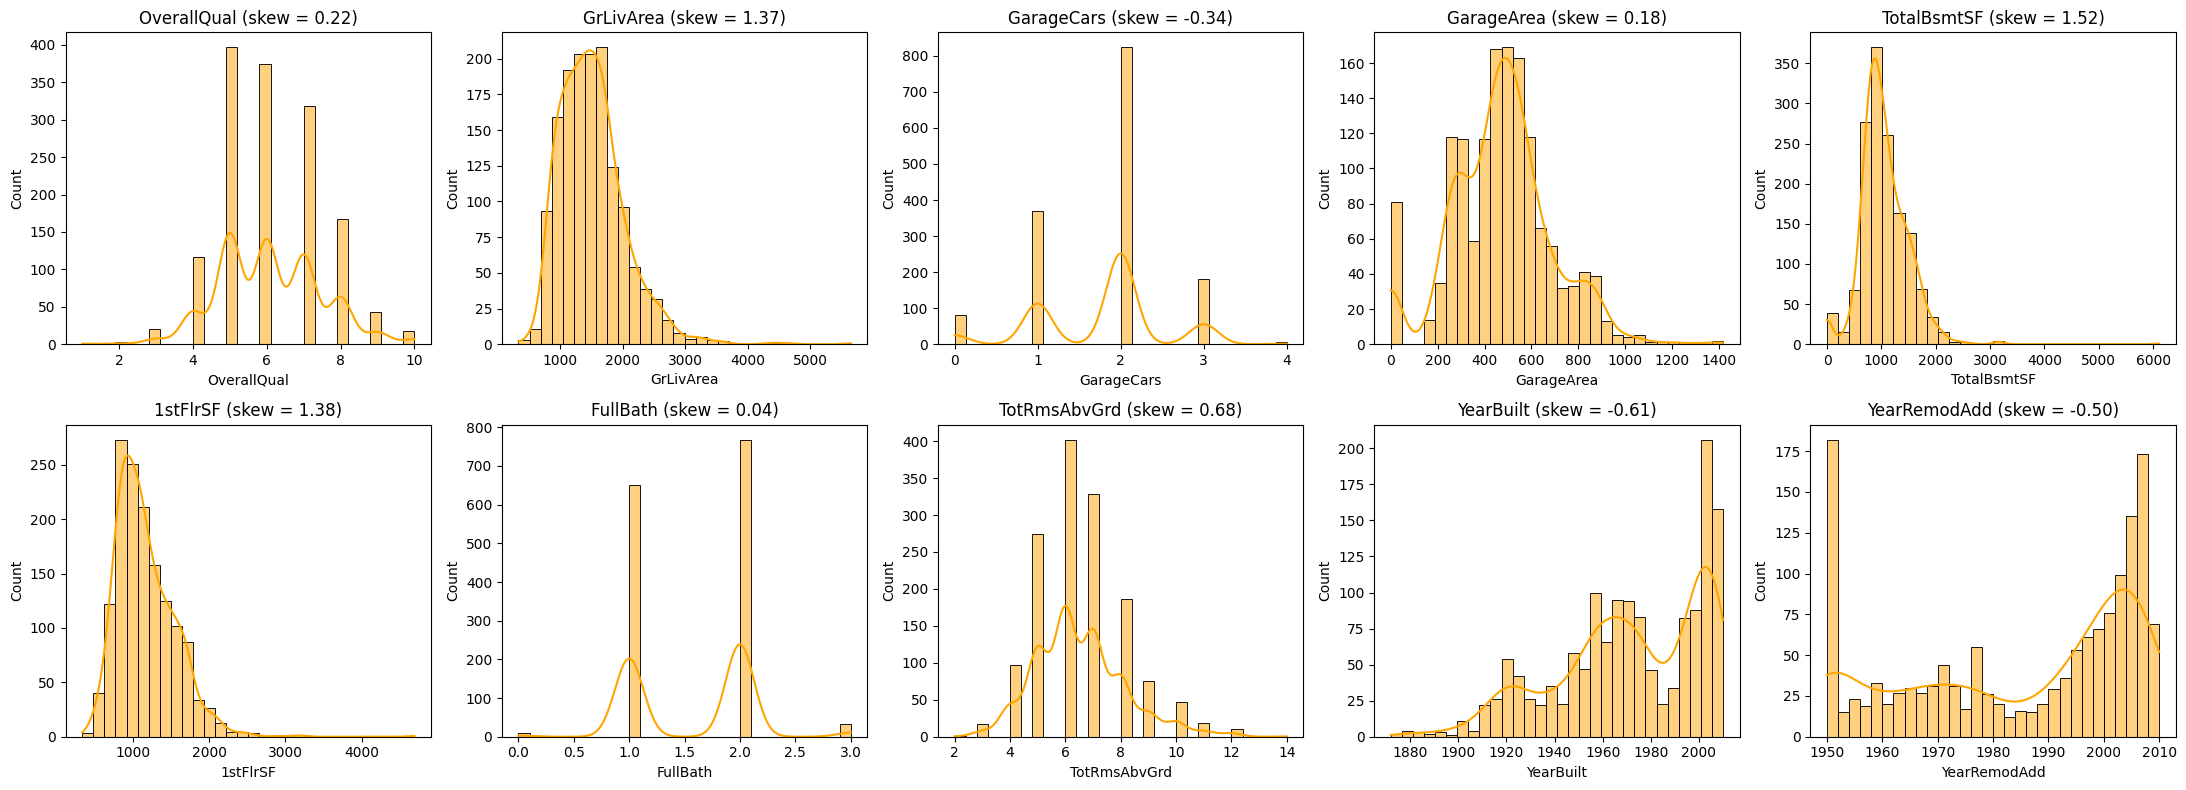

In [9]:
important_num_cols = ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
                      '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd']

skew_table = df[num_cols].skew().sort_values(ascending=False)
print("Skewness of the important features:")
display(skew_table[important_num_cols].round(2))
print("\nHighly skewed numerical features (|skew| > 0.75):")
display(skew_table[skew_table.abs() > 0.75].round(2))

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.flatten(), important_num_cols):
    sns.histplot(df[col], kde=True, bins=30, color='orange', ax=ax)
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
plt.tight_layout()
plt.show()

### 2.4 Analysis of categorical features
- [ ] Countplots
- [ ] Boxplots vs SalePrice

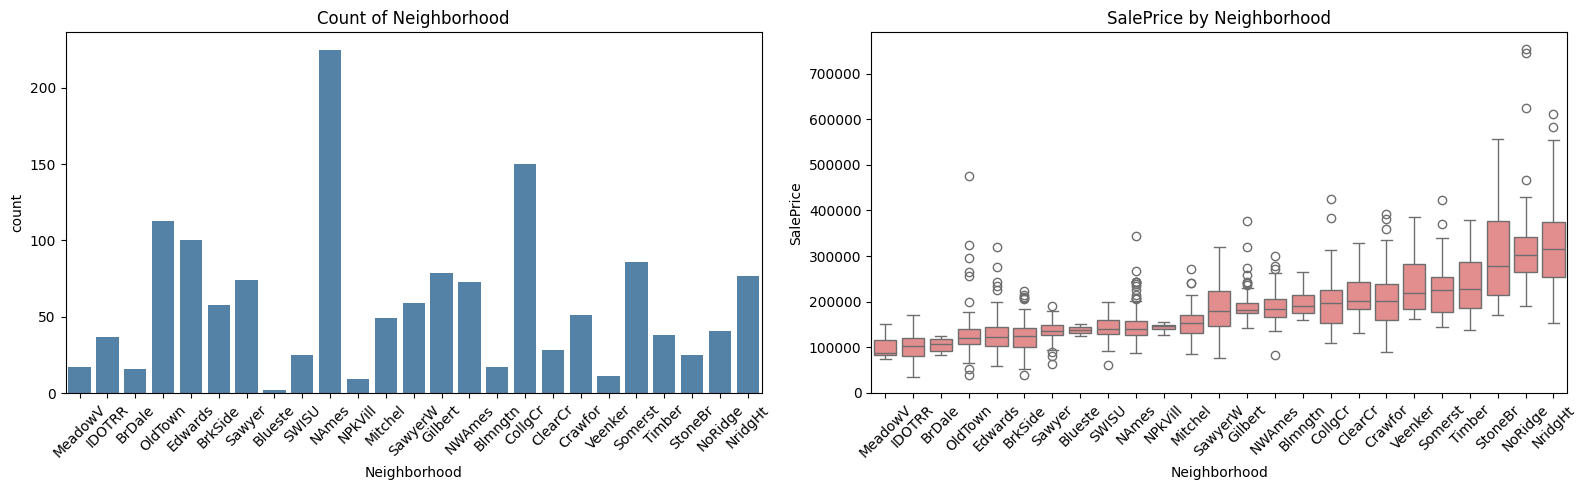

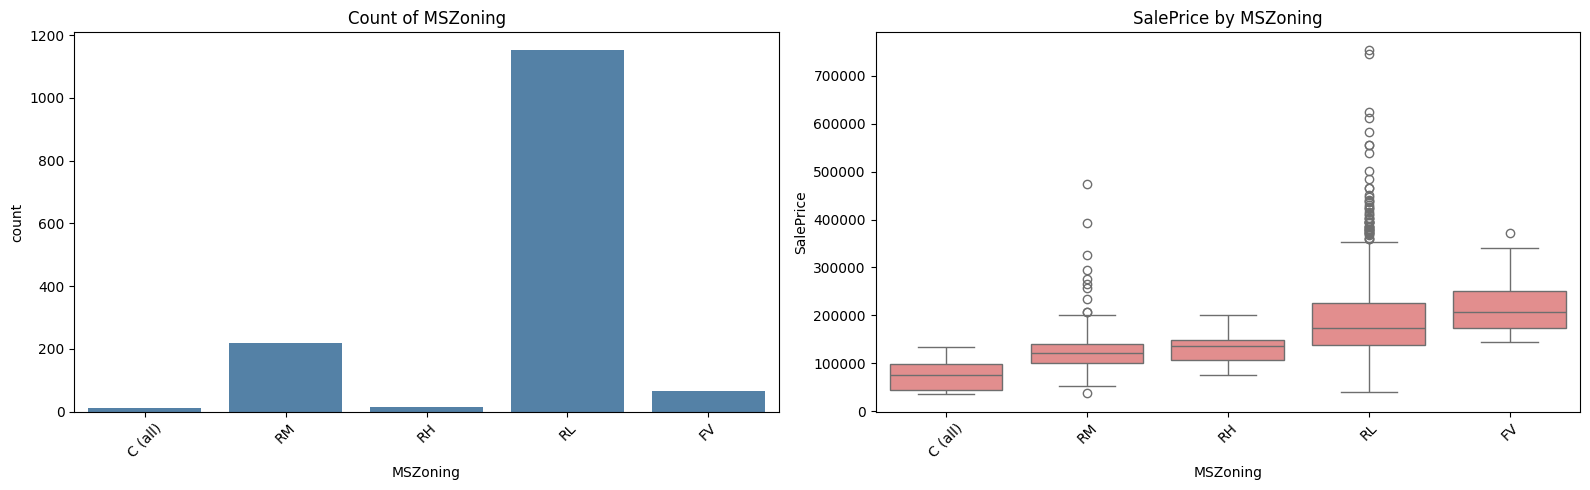

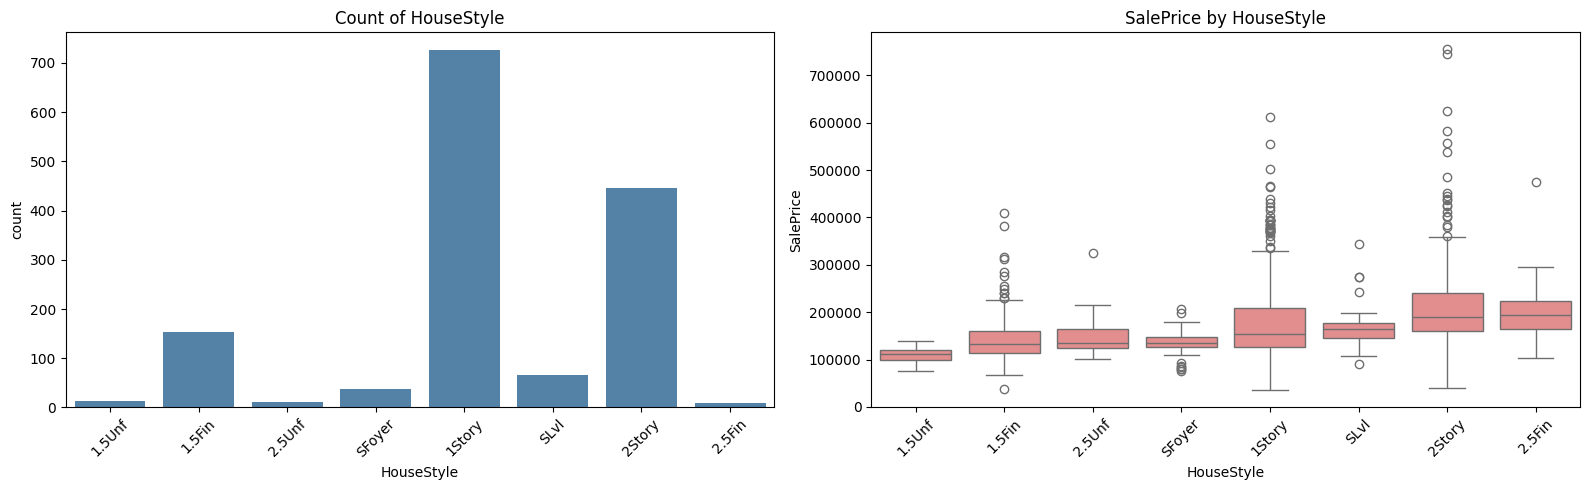

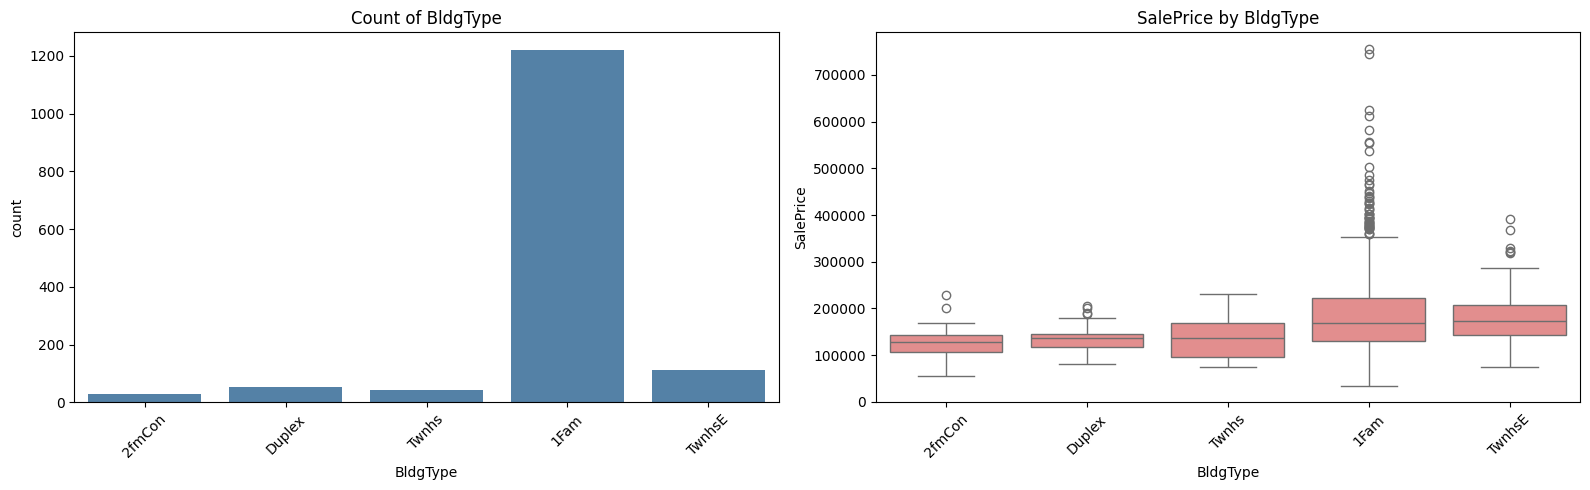

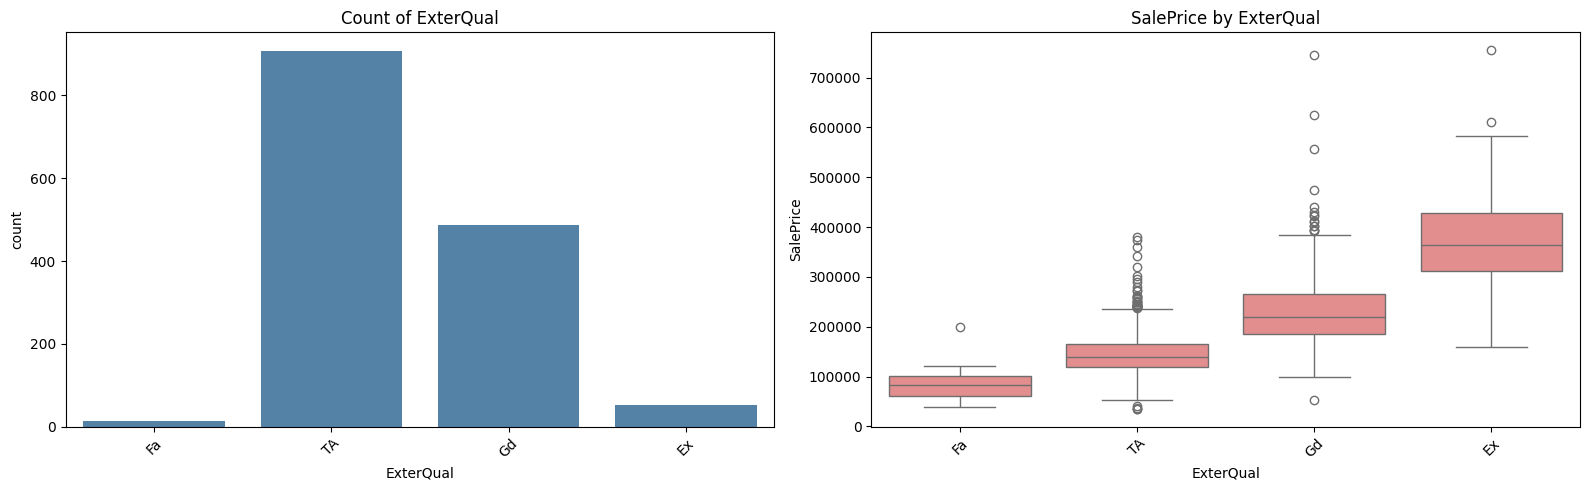

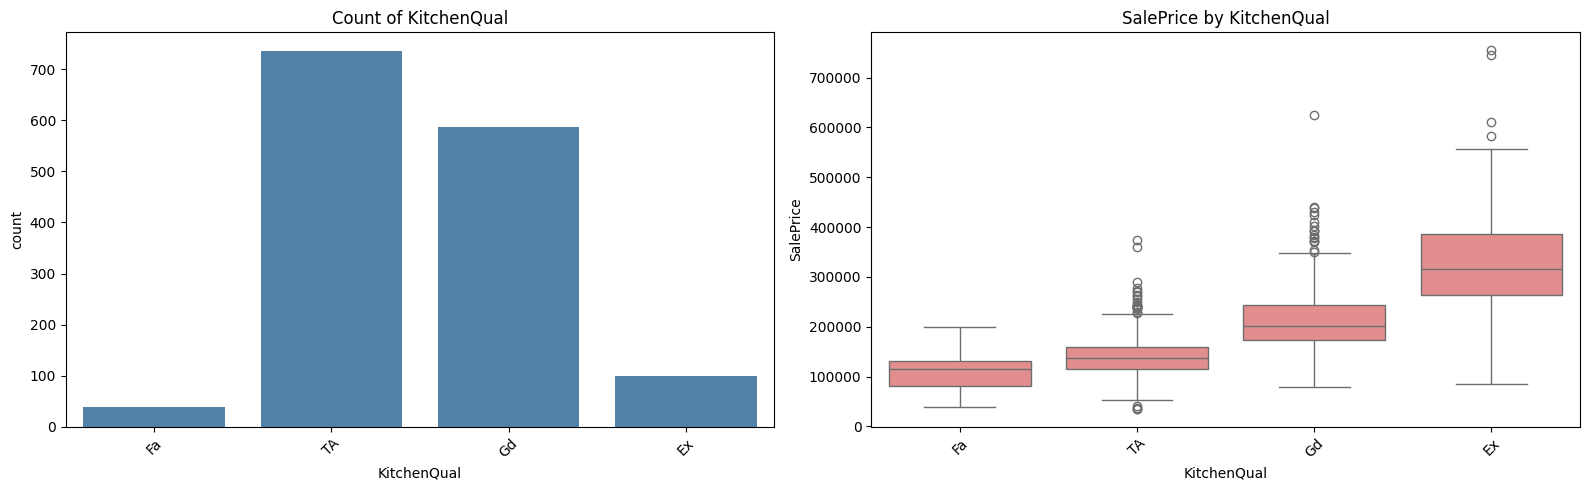

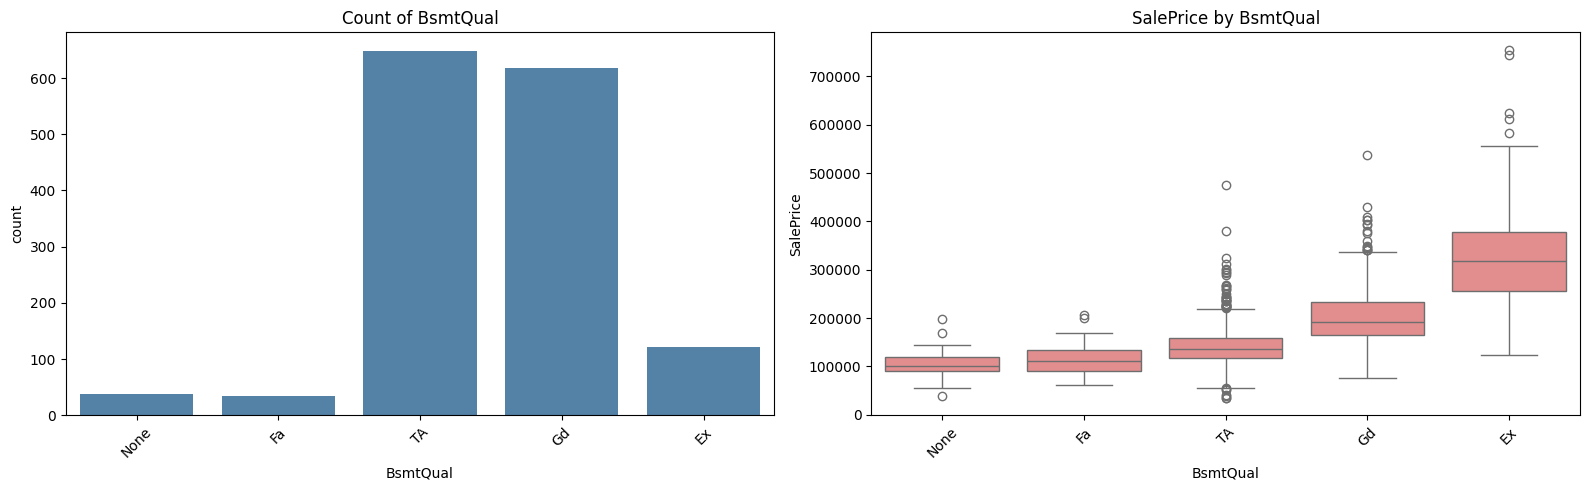

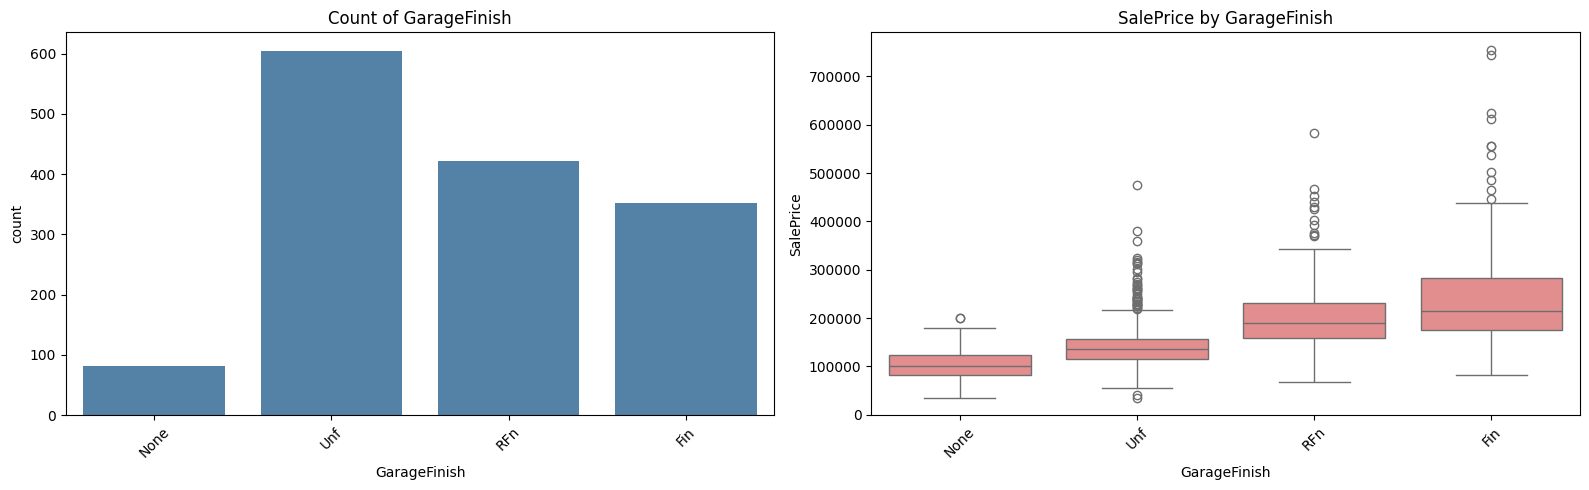

In [10]:
def cat_plots(col, order=None):
    """Countplot + boxplot vs SalePrice. Ordinal columns use their real order,
    nominal columns are sorted by median price."""
    if order is None:
        order = df.groupby(col)['SalePrice'].median().sort_values().index.tolist()
    else:
        order = [o for o in order if o in df[col].unique()]
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    sns.countplot(data=df, x=col, order=order, color='steelblue', ax=axes[0])
    axes[0].set_title(f'Count of {col}')
    sns.boxplot(data=df, x=col, y='SalePrice', order=order, color='lightcoral', ax=axes[1])
    axes[1].set_title(f'SalePrice by {col}')
    for ax in axes:
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

# Nominal
for col in ['Neighborhood', 'MSZoning', 'HouseStyle', 'BldgType']:
    cat_plots(col)
# Ordinal (real order)
for col in ['ExterQual', 'KitchenQual', 'BsmtQual', 'GarageFinish']:
    cat_plots(col, order=ordinal_mapping[col])

### 2.5 Outliers
- [ ] Detection (boxplot / IQR / scatter)
- [ ] Analysis and decision

,feature,lower,upper,n_outliers
0,SalePrice,3938,340038,61
1,GrLivArea,159,2748,31
2,TotalBsmtSF,42,2052,61
3,LotArea,1482,17674,69
4,GarageArea,-28,938,21


,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
691,692,4316,755000,10,Normal
1182,1183,4476,745000,10,Abnorml
1298,1299,5642,160000,10,Partial


Suspicious outliers (Id): [524, 1299]


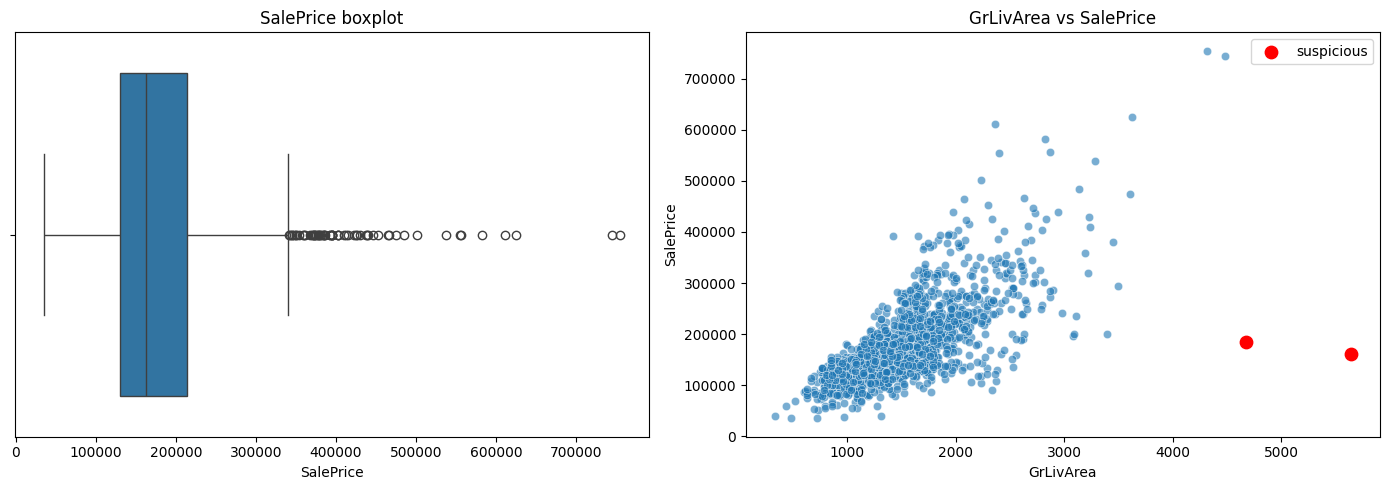

In [11]:
# IQR rule on several features
rows = []
for col in ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'LotArea', 'GarageArea']:
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({'feature': col, 'lower': round(lo), 'upper': round(hi),
                 'n_outliers': int(((df[col] < lo) | (df[col] > hi)).sum())})
display(pd.DataFrame(rows))

# Houses with very large living area: are their prices consistent with their size?
display(df[df['GrLivArea'] > 4000][['Id', 'GrLivArea', 'SalePrice', 'OverallQual', 'SaleCondition']])

# Suspicious = huge area but low price
outlier_ids = df.loc[(df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000), 'Id'].tolist()
print("Suspicious outliers (Id):", outlier_ids)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df['SalePrice'], ax=axes[0])
axes[0].set_title('SalePrice boxplot')
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', alpha=0.6, ax=axes[1])
sus = df[df['Id'].isin(outlier_ids)]
axes[1].scatter(sus['GrLivArea'], sus['SalePrice'], color='red', s=80, label='suspicious')
axes[1].set_title('GrLivArea vs SalePrice'); axes[1].legend()
plt.tight_layout()
plt.show()

**Outlier decision:** Houses `Id 524` and `Id 1299` have a very large living area (4,676 and 5,642 sq ft) but low prices ($184,750 and $160,000). Both have `SaleCondition = Partial` (house not completed when assessed), so their price does not reflect their size. We recommend **removing these 2 rows before the train/test split in Part B** (they would mislead the model). Houses `Id 692` and `Id 1183` are also above 4,000 sq ft but their prices ($755K, $745K) are consistent with their size, so they are **kept**. Other IQR outliers (e.g. expensive houses, large lots) are real data, so we keep them and handle skewness with transformations instead.

### 2.6 Correlation analysis
- [ ] Heatmap
- [ ] Top features correlated with SalePrice
- [ ] Multicollinearity between features

Top 10 features correlated with SalePrice:


OverallQual     0.79
GrLivArea       0.71
GarageCars      0.64
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
FullBath        0.56
TotRmsAbvGrd    0.53
YearBuilt       0.52
YearRemodAdd    0.51
Name: SalePrice, dtype: float64

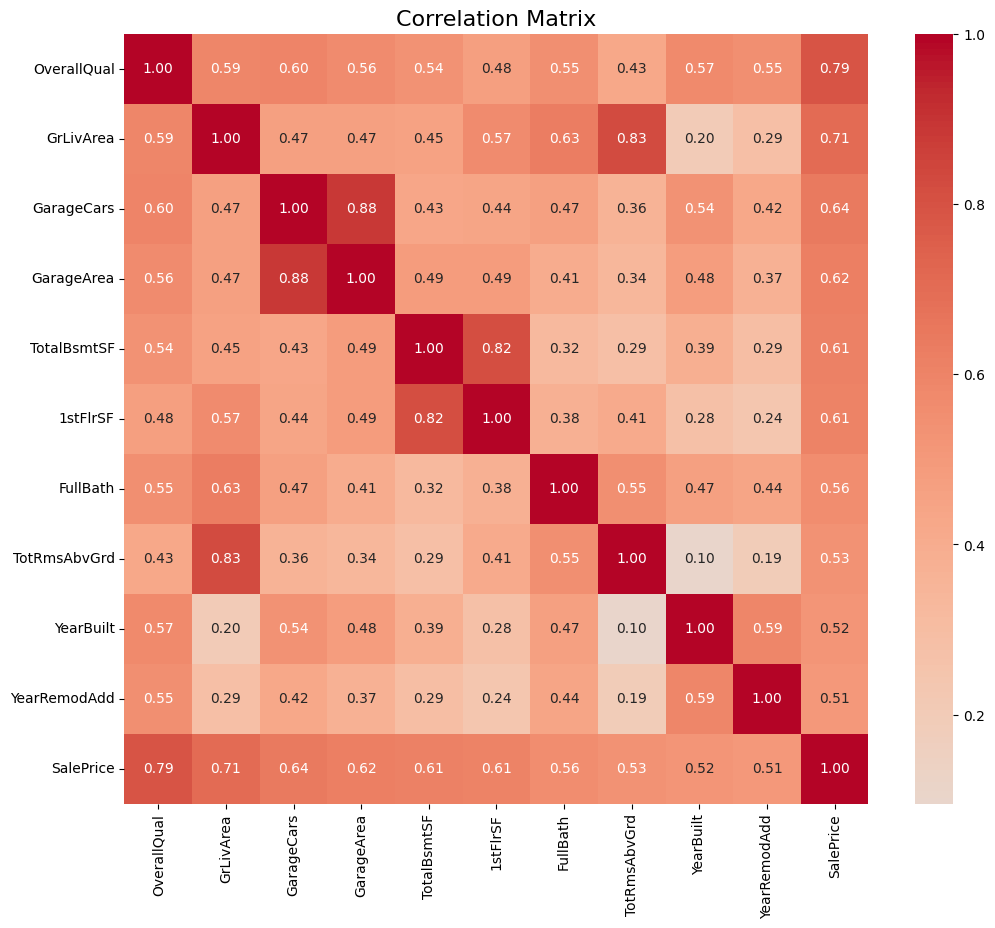

Highly correlated feature pairs (> 0.8):


GarageCars   GarageArea      0.88
YearBuilt    GarageYrBlt     0.83
GrLivArea    TotRmsAbvGrd    0.83
TotalBsmtSF  1stFlrSF        0.82
dtype: float64

In [12]:
# Top 10 features correlated with SalePrice
sale_price_corr = (df[num_cols + ['SalePrice']].corr()['SalePrice']
                   .drop('SalePrice').sort_values(key=abs, ascending=False).head(10))
print("Top 10 features correlated with SalePrice:")
display(sale_price_corr.round(2))

# Heatmap (SalePrice included)
plt.figure(figsize=(12, 10))
sns.heatmap(df[important_num_cols + ['SalePrice']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix', fontsize=16)
plt.show()

# Multicollinearity: feature pairs with |corr| > 0.8
corr_abs = df[num_cols].corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
high_pairs = upper.stack().loc[lambda s: s > 0.8].sort_values(ascending=False)
print("Highly correlated feature pairs (> 0.8):")
display(high_pairs.round(2))

### 2.7 Relationships between key features and SalePrice
- [ ] Scatterplots
- [ ] Barplots / boxplots

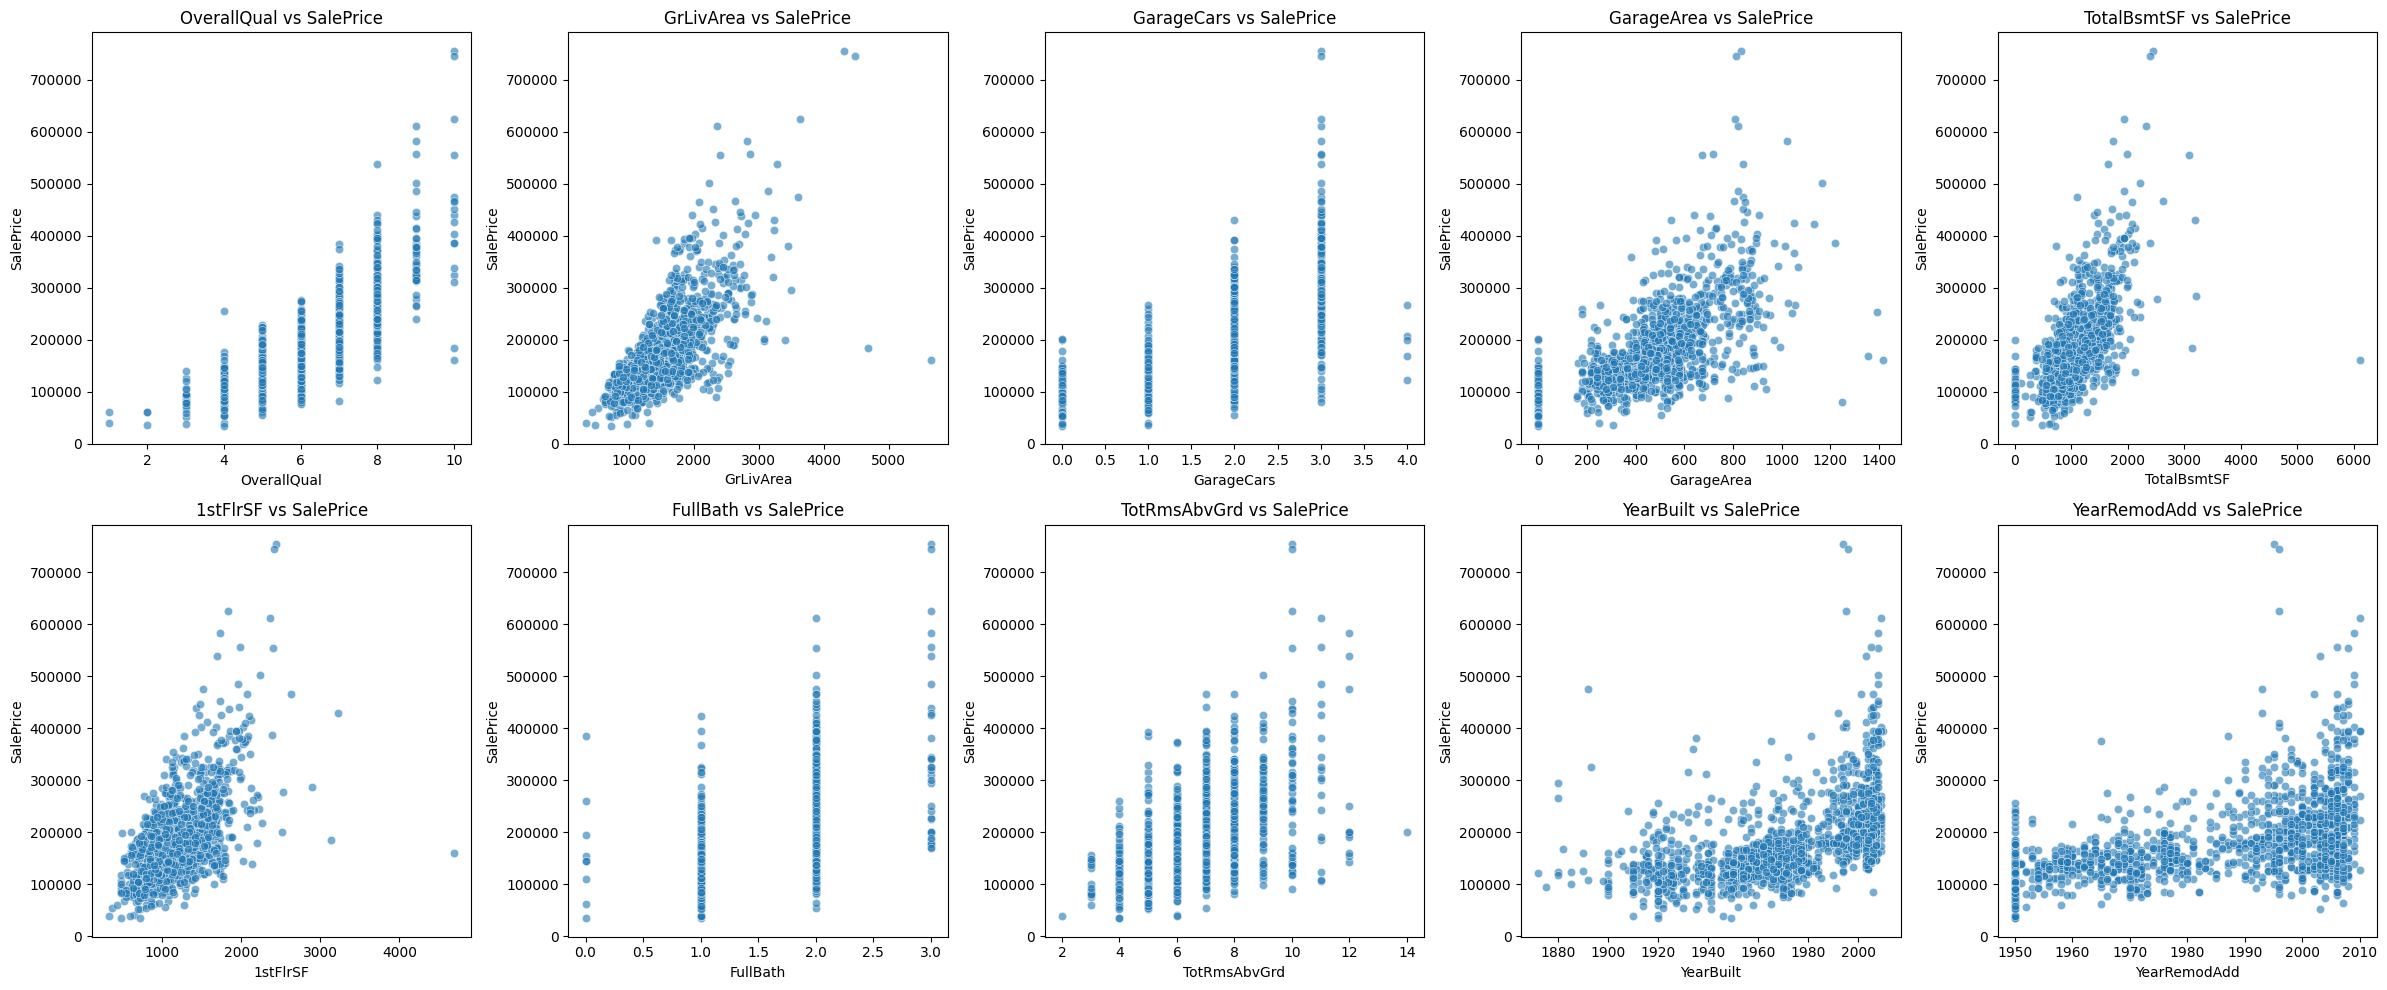

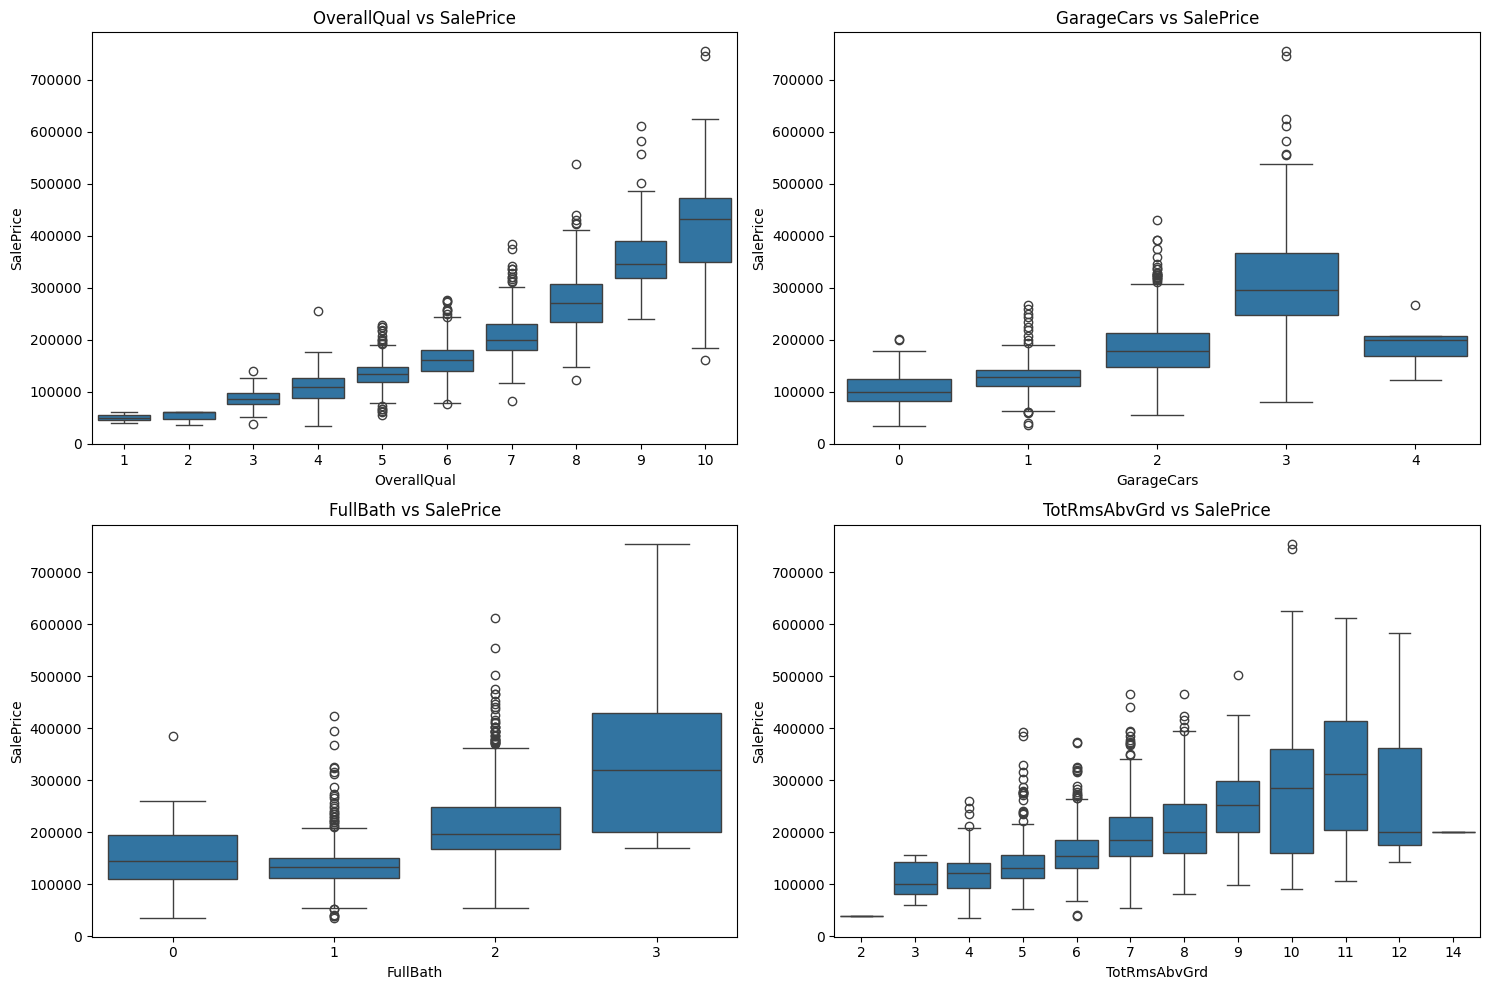

In [13]:
key_features = ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd']
fig, axes = plt.subplots(2, 5, figsize=(24, 10))

for ax, feature in zip(axes.flatten(), key_features):
    sns.scatterplot(
        data=df,
        x=feature,
        y='SalePrice',
        alpha=0.6,
        ax=ax
    )
    ax.set_title(f'{feature} vs SalePrice')
    ax.set_xlabel(feature)
    ax.set_ylabel('SalePrice')

plt.tight_layout()
plt.show()

box_features = ['OverallQual', 'GarageCars', 'FullBath', 'TotRmsAbvGrd']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, feature in zip(axes.flatten(), box_features):
    sns.boxplot(
        data=df,
        x=feature,
        y='SalePrice',
        ax=ax
    )
    ax.set_title(f'{feature} vs SalePrice')
    ax.set_xlabel(feature)
    ax.set_ylabel('SalePrice')

plt.tight_layout()
plt.show()

**Explanation of the main patterns found in the EDA:**

- **SalePrice is right-skewed** (skew = 1.88): most houses are cheap and a few are very expensive (max $755K vs median $163K). After `log1p` the skew drops to 0.12, so the log transform makes the target almost symmetric and is justified for modelling.
- **Skewed features:** `TotalBsmtSF` (1.52), `1stFlrSF` (1.38) and `GrLivArea` (1.37) are right-skewed. Many other columns are extremely skewed (`LotArea` 12.2, `MiscVal` 24.5, `PoolArea` 14.8) because most houses have a value of 0 or a few huge values. These are candidates for a log transform in Part B.
- **Quality drives price:** median price rises steadily with `OverallQual`, from $50K (quality 1) to $432K (quality 10). `ExterQual` and `KitchenQual` show the same pattern (e.g. kitchen: Fair $115K, Typical $137K, Good $201K, Excellent $317K).
- **Size matters:** `GrLivArea` (0.71), `GarageCars` (0.64), `TotalBsmtSF` (0.61) are strongly and positively correlated with price. Median price by garage capacity: 0 cars $100K, 1 car $128K, 2 cars $178K, 3 cars $295K.
- **Neighborhood matters:** median price is lowest in MeadowV ($88K), IDOTRR ($103K) and BrDale ($106K) and highest in NridgHt ($315K), NoRidge ($301K) and StoneBr ($278K).
- **Newer houses cost more:** `YearBuilt` (0.52) and `YearRemodAdd` (0.51) are positively correlated with price.
- **Multicollinearity:** several features measure almost the same thing: `GarageCars`/`GarageArea` (0.88), `GrLivArea`/`TotRmsAbvGrd` (0.83), `YearBuilt`/`GarageYrBlt` (0.83), `TotalBsmtSF`/`1stFlrSF` (0.82). This matters for interpreting coefficients and feature importance later.
- **Outliers:** two houses (Id 524 and 1299) are huge but cheap and were `Partial` sales; they are recommended for removal in Part B (see decision above).

#### 📝 Section Summary
EDA showed that `SalePrice` is strongly right-skewed (1.88) and becomes almost symmetric after a log transform (0.12). The strongest correlates of price are `OverallQual` (0.79), `GrLivArea` (0.71) and `GarageCars` (0.64), and price also varies clearly by neighborhood (median from $88K in MeadowV to $315K in NridgHt). Several features are highly collinear (e.g. `GarageCars`/`GarageArea` 0.88), and many numerical features are skewed and need transformation. Two suspicious outliers (Id 524 and 1299) were identified and recommended for removal before the split.

## 3. Data Analysis & Insights


### 3.1 Housing prices
- [ ] Mean, median, min, max SalePrice
- [ ] Highest and lowest priced houses
- [ ] Price vs living area (`GrLivArea`)
- [ ] Characteristics of the most expensive houses

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Minimum SalePrice: 34900
Maximum SalePrice: 755000
Correlation GrLivArea vs SalePrice: 0.71


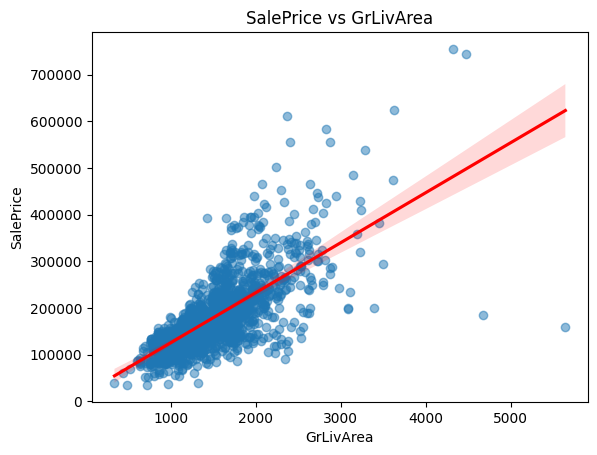


--- Key Characteristics of Top 10 Most Expensive Houses ---


,SalePrice,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,YearRemodAdd
691,755000,10,4316,3,832,2444,2444,3,10,1994,1995
1182,745000,10,4476,3,813,2396,2411,3,10,1996,1996
1169,625000,10,3627,3,807,1930,1831,3,10,1995,1996
898,611657,9,2364,3,820,2330,2364,2,11,2009,2010
803,582933,9,2822,3,1020,1734,1734,3,12,2008,2009
1046,556581,9,2868,3,716,1992,1992,3,11,2005,2006
440,555000,10,2402,3,672,3094,2402,2,10,2008,2008
769,538000,8,3279,3,841,1650,1690,3,12,2003,2003
178,501837,9,2234,3,1166,2216,2234,2,9,2008,2009
798,485000,9,3140,3,820,1926,1966,3,11,2008,2009


5 cheapest houses:


,Id,SalePrice,GrLivArea,OverallQual,YearBuilt,Neighborhood,SaleCondition
495,496,34900,720,4,1920,IDOTRR,Abnorml
916,917,35311,480,2,1949,IDOTRR,Abnorml
968,969,37900,968,3,1910,OldTown,Abnorml
533,534,39300,334,1,1946,BrkSide,Normal
30,31,40000,1317,4,1920,IDOTRR,Normal


,Top 5% (median),All houses (median)
GrLivArea,2364.0,1464.0
OverallQual,9.0,6.0
GarageCars,3.0,2.0
TotalBsmtSF,1746.0,991.5
YearBuilt,2005.0,1973.0


Share with OverallQual >= 8: 0.92
Top neighborhoods: {'NridgHt': 29, 'NoRidge': 15, 'StoneBr': 9}


In [14]:
display(df['SalePrice'].describe())
min_price = df['SalePrice'].min()
max_price = df['SalePrice'].max()
print(f"Minimum SalePrice: {min_price}")
print(f"Maximum SalePrice: {max_price}")
#price vs living area
print(f"Correlation GrLivArea vs SalePrice: {df['GrLivArea'].corr(df['SalePrice']):.2f}")
sns.regplot(data=df, x='GrLivArea', y='SalePrice', scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
plt.title('SalePrice vs GrLivArea'); plt.show()
#most expensive
top_10_expensive = df.nlargest(10, 'SalePrice')
key_features = ['SalePrice','OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd']


key_features = [col for col in key_features if col in df.columns]

print('\n--- Key Characteristics of Top 10 Most Expensive Houses ---')
display(top_10_expensive[key_features])

#cheapest
cols = ['Id', 'SalePrice', 'GrLivArea', 'OverallQual', 'YearBuilt', 'Neighborhood', 'SaleCondition']
print("5 cheapest houses:")
display(df.nsmallest(5, 'SalePrice')[cols])

#characteristics of the top 5% most expensive houses vs all houses
top5 = df[df['SalePrice'] >= df['SalePrice'].quantile(0.95)]
feats = ['GrLivArea', 'OverallQual', 'GarageCars', 'TotalBsmtSF', 'YearBuilt']
display(pd.DataFrame({'Top 5% (median)': top5[feats].median(), 'All houses (median)': df[feats].median()}))
print("Share with OverallQual >= 8:", round((top5['OverallQual'] >= 8).mean(), 2))
print("Top neighborhoods:", top5['Neighborhood'].value_counts().head(3).to_dict())


Price and living area are strongly positively related (r = 0.71): larger houses cost more. A few very large houses (>4,000 sq ft) break the pattern (see outliers, Section 2.5).

The top 5% of houses (price >= $326K) are larger (median 2,364 vs 1,464 sq ft), higher quality (median OverallQual 9 vs 6; 92% have quality >= 8), newer (built 2005 vs 1973) and have a 3-car garage. They are concentrated in NridgHt (29 of 73) and NoRidge (15).

### 3.2 Neighborhood analysis
- [ ] Top 3 neighborhoods by average price + their averages
- [ ] Lowest 3 neighborhoods by average price + their averages
- [ ] Neighborhood with the most houses
- [ ] Is the relationship between neighborhood and price strong?


--- Top 3 Neighborhoods by Average SalePrice ---


Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Name: SalePrice, dtype: float64


--- Average SalePrice of Top 3 Neighborhoods ---


Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Name: SalePrice, dtype: float64


--- Lowest 3 Neighborhoods by Average SalePrice ---


Neighborhood
MeadowV     98576.470588
IDOTRR     100123.783784
BrDale     104493.750000
Name: SalePrice, dtype: float64


--- Neighborhoods with Highest Number of Houses ---


Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Name: Id, dtype: int64

Share of SalePrice variance explained by Neighborhood: 0.55


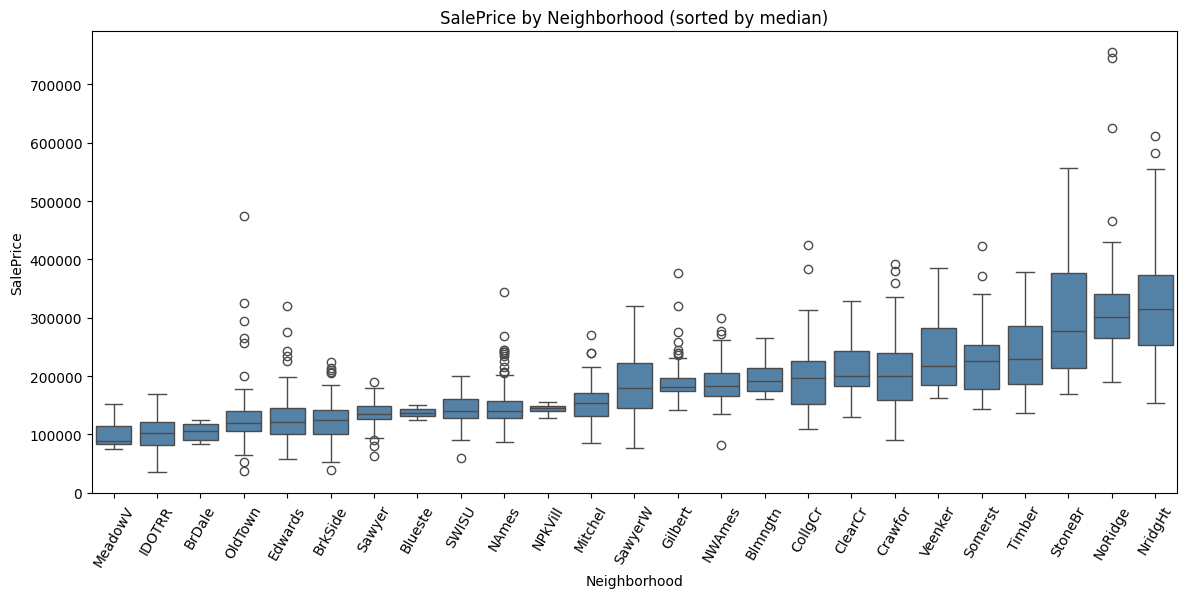

In [15]:
top_three_neighbours=df.groupby('Neighborhood')['SalePrice'].mean().nlargest(3)
print("\n--- Top 3 Neighborhoods by Average SalePrice ---")
display(top_three_neighbours)
avg_three_price_by_neighborhood = df.groupby('Neighborhood')['SalePrice'].mean().nlargest(3).sort_values(ascending=False)
print("\n--- Average SalePrice of Top 3 Neighborhoods ---")
display(avg_three_price_by_neighborhood)
lowest_three_neighbours=df.groupby('Neighborhood')['SalePrice'].mean().nsmallest(3)
print("\n--- Lowest 3 Neighborhoods by Average SalePrice ---")
display(lowest_three_neighbours)
hishest_num_of_neighbourhood_houses = df.groupby('Neighborhood')['Id'].count().nlargest()
print("\n--- Neighborhoods with Highest Number of Houses ---")
display(hishest_num_of_neighbourhood_houses)
overall_mean = df['SalePrice'].mean()
ss_between = sum(len(g) * (g.mean() - overall_mean) ** 2
                 for _, g in df.groupby('Neighborhood')['SalePrice'])
ss_total = ((df['SalePrice'] - overall_mean) ** 2).sum()
print(f"Share of SalePrice variance explained by Neighborhood: {ss_between / ss_total:.2f}")
order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=order, color='steelblue')
plt.xticks(rotation=60); plt.title('SalePrice by Neighborhood (sorted by median)')
plt.show()


**Answer:** Yes, the relationship is strong. Neighborhood explains about 55% of the variance in SalePrice; the average price ranges from $98,576 (MeadowV) to $335,295 (NoRidge), about 3.4x.

### 3.3 Time-based analysis
- [ ] Month with highest average price
- [ ] Month with lowest average price
- [ ] Month with the most sales
- [ ] Does the average price vary through the year?

Highest: month 9 ($195,683)
Lowest: month 4 ($171,503)


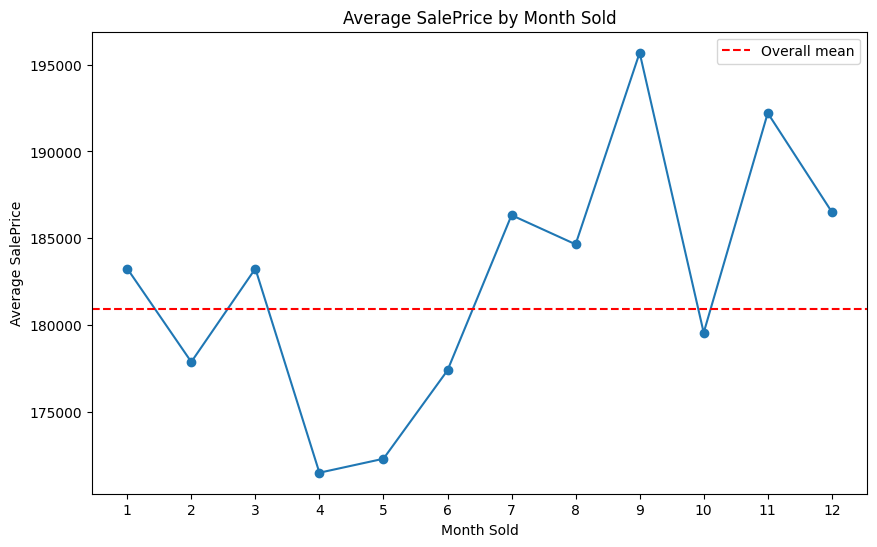

Gap between best and worst month: 13.4% of the mean
Share of price variance explained by month: 0.007


C:\Users\elmoulll\AppData\Local\Temp\ipykernel_32728\2783976436.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=monthly_house_count.index, y=monthly_house_count.values, palette='viridis')


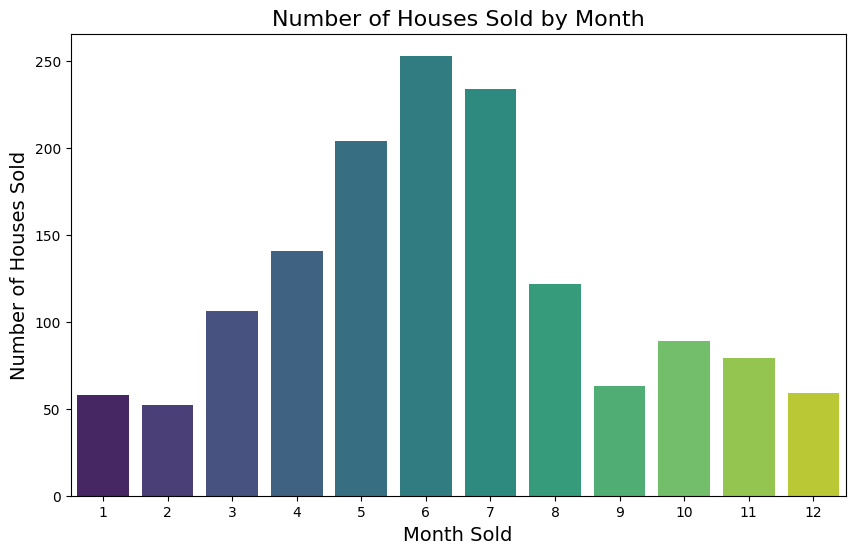

Month with highest number of houses sold: 6 (253 houses)


In [16]:
monthly_mean = df.groupby('MoSold')['SalePrice'].mean()
print(f"Highest: month {monthly_mean.idxmax()} (${monthly_mean.max():,.0f})")
print(f"Lowest: month {monthly_mean.idxmin()} (${monthly_mean.min():,.0f})")
plt.figure(figsize=(10, 6))
plt.plot(monthly_mean.index, monthly_mean.values, marker='o')
plt.axhline(df['SalePrice'].mean(), color='red', linestyle='--', label='Overall mean')
plt.xticks(range(1, 13)); plt.xlabel('Month Sold'); plt.ylabel('Average SalePrice'); plt.legend()
plt.title('Average SalePrice by Month Sold'); plt.show()
spread = (monthly_mean.max() - monthly_mean.min()) / df['SalePrice'].mean() * 100
overall_mean = df['SalePrice'].mean()
ss_between = sum(len(g) * (g.mean() - overall_mean) ** 2 for _, g in df.groupby('MoSold')['SalePrice'])
ss_total = ((df['SalePrice'] - overall_mean) ** 2).sum()
print(f"Gap between best and worst month: {spread:.1f}% of the mean")
print(f"Share of price variance explained by month: {ss_between / ss_total:.3f}")
#highest number of house sold in a month
monthly_house_count = df.groupby('MoSold')['Id'].count()
plt.figure(figsize=(10, 6))
sns.barplot(x=monthly_house_count.index, y=monthly_house_count.values, palette='viridis')
plt.title('Number of Houses Sold by Month', fontsize=16)
plt.xlabel('Month Sold', fontsize=14)
plt.ylabel('Number of Houses Sold', fontsize=14)
plt.show()
#highest number of house sold in a month
highest_sold_month = monthly_house_count.idxmax()
print(f"Month with highest number of houses sold: {highest_sold_month} ({monthly_house_count.max()} houses)")


**Answer:** Only slightly. The average price moves between $171K (April) and $196K (September), a gap of about 13% of the mean, and month explains less than 1% of price variance. So the time of year has almost no real effect on price. (Sales volume, however, peaks in June, with 253 sales.)

### 3.4 House characteristics
- [ ] Number of bedrooms vs price
- [ ] Number of bathrooms vs price
- [ ] `OverallQual` vs price
- [ ] Garage capacity vs price
- [ ] Basement vs no basement
- [ ] House age vs price

1. Bedrooms Above Grade (BedroomAbvGr) vs SalePrice


,BedroomAbvGr,Count,Median_Price,Mean_Price
0,0,6,202500.0,221493.166667
1,1,50,145250.0,173162.420000
2,2,358,137250.0,158197.659218
3,3,804,169945.0,181056.870647
4,4,213,193500.0,220421.253521
5,5,21,161500.0,180819.047619
6,6,7,141000.0,143779.000000
7,8,1,200000.0,200000.000000


C:\Users\elmoulll\AppData\Local\Temp\ipykernel_32728\4266692992.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='BedroomAbvGr', y='SalePrice', palette='Blues')


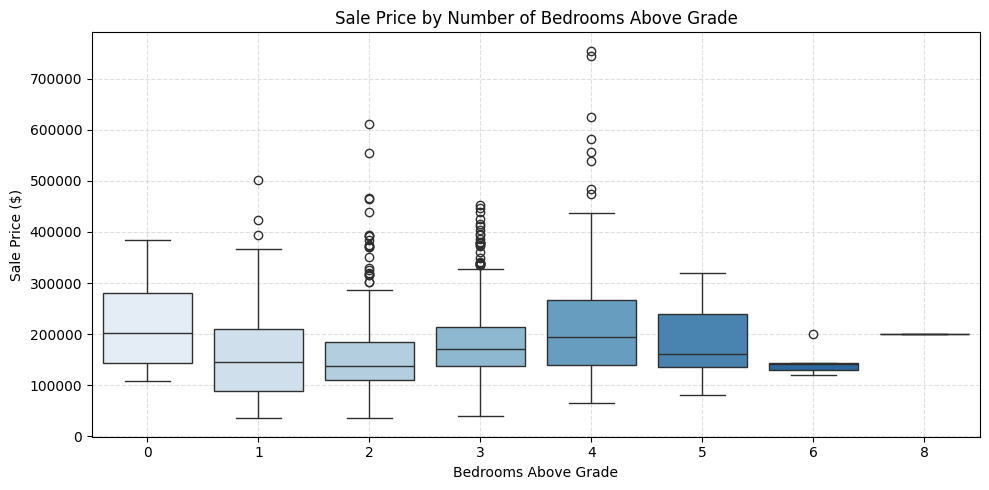


--- Interpretation (Bedrooms) ---
Median price is higher with 4 bedrooms than with 3, while the 5- and 6-bedroom groups are small (21 and 7 houses).

2. Full Bathrooms (FullBath) vs SalePrice


,FullBath,Count,Median_Price,Mean_Price
0,0,9,145000.0,165200.888889
1,1,650,132375.0,134751.440000
2,2,768,196750.0,213009.825521
3,3,33,320000.0,347822.909091


C:\Users\elmoulll\AppData\Local\Temp\ipykernel_32728\4266692992.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='FullBath', y='SalePrice', palette='Greens')


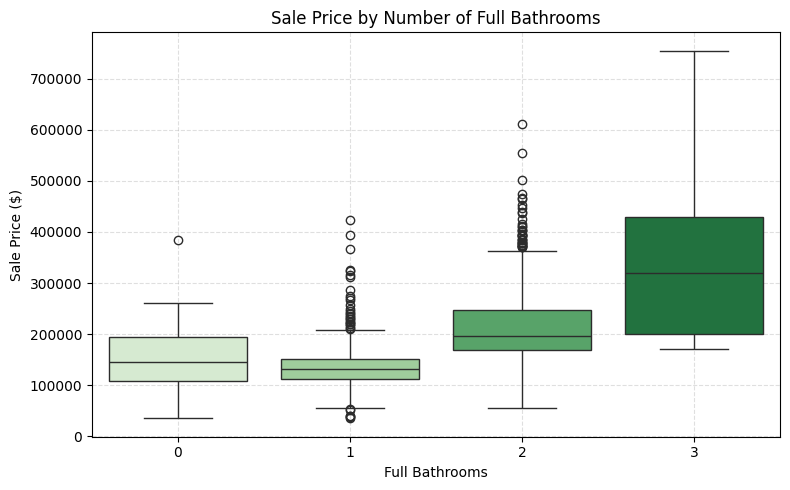


--- Interpretation (Bathrooms) ---
Full bathrooms act as a strong value multiplier. Homes with 3 full bathrooms command a significantly higher median price than 1 or 2 bathroom homes, reflecting luxury preferences.

3. Overall Quality (OverallQual) vs SalePrice


,OverallQual,Count,Median_Price,Mean_Price
0,1,2,50150.0,50150.000000
1,2,3,60000.0,51770.333333
2,3,20,86250.0,87473.750000
3,4,116,108000.0,108420.655172
4,5,397,133000.0,133523.347607
5,6,374,160000.0,161603.034759
6,7,319,200141.0,207716.423197
7,8,168,269750.0,274735.535714
8,9,43,345000.0,367513.023256
9,10,18,432390.0,438588.388889


C:\Users\elmoulll\AppData\Local\Temp\ipykernel_32728\4266692992.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


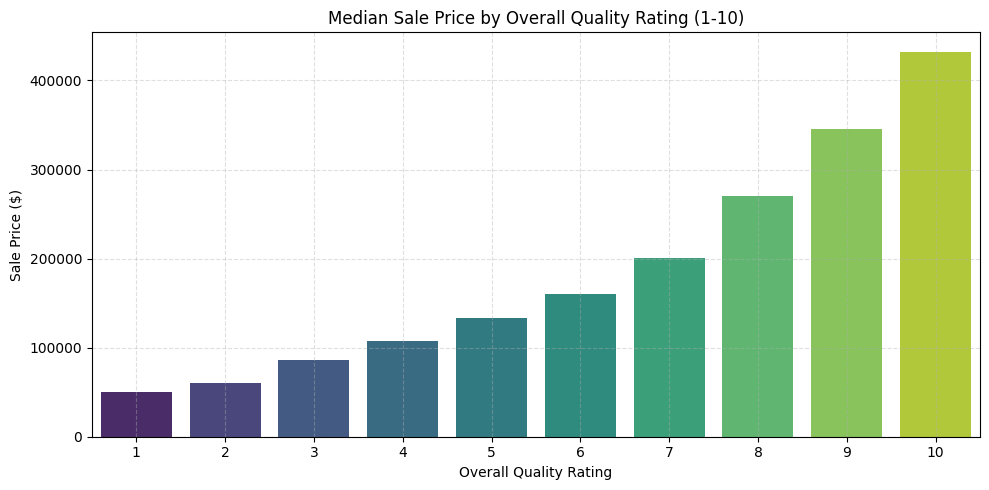


--- Interpretation (Overall Quality) ---
Strong positive relationship (r = 0.79): median price rises from $50,150 (quality 1) to $432,390 (quality 10).

4. Garage Capacity (GarageCars) vs SalePrice


,GarageCars,Count,Median_Price,Mean_Price
0,0,81,100000.0,103317.283951
1,1,369,128000.0,128116.688347
2,2,824,177750.0,183851.663835
3,3,181,295000.0,309636.121547
4,4,5,200000.0,192655.800000


C:\Users\elmoulll\AppData\Local\Temp\ipykernel_32728\4266692992.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='GarageCars', y='SalePrice', palette='Purples')


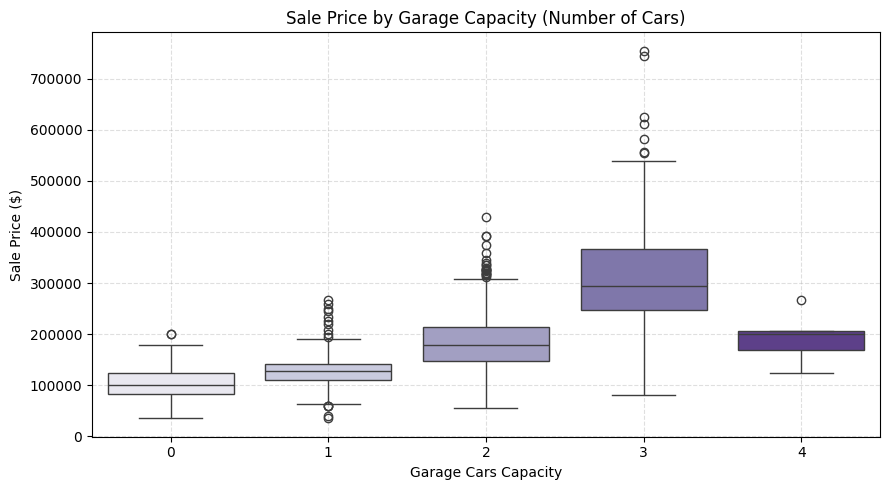


--- Interpretation (Garage Capacity) ---
Garage capacity shows diminishing returns: moving from 0 to 2 cars yields a substantial price premium, and 3 cars reaches peak median price. However, 4-car garages plateau or slightly drop. Only 5 houses have 4-car garages, too few to draw a conclusion.

5. Basement Presence (Has_Basement) vs SalePrice


,Has_Basement,Count,Median_Price,Mean_Price
0,Has Basement,1423,165000.0,182878.277583
1,No Basement,37,101800.0,105652.891892


C:\Users\elmoulll\AppData\Local\Temp\ipykernel_32728\4266692992.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


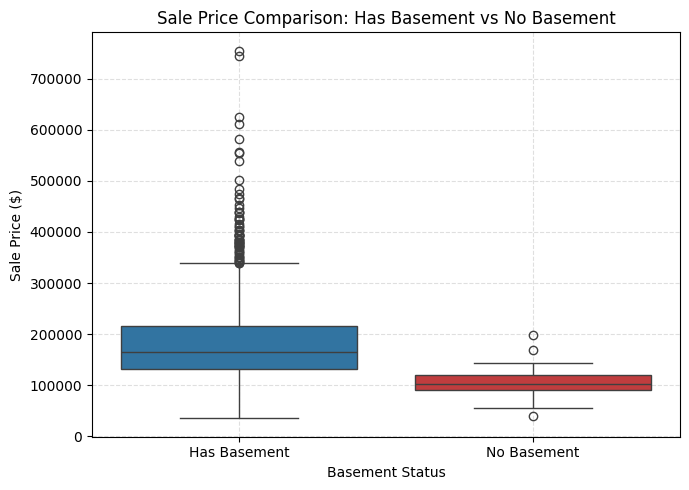


--- Interpretation (Basement) ---
Homes with a basement achieve a median sale price of $165,000.00 versus $101,800.00 for homes without one. This represents a +62.1% baseline premium for basement foundation.

6. House Age at Sale (House_Age) vs SalePrice


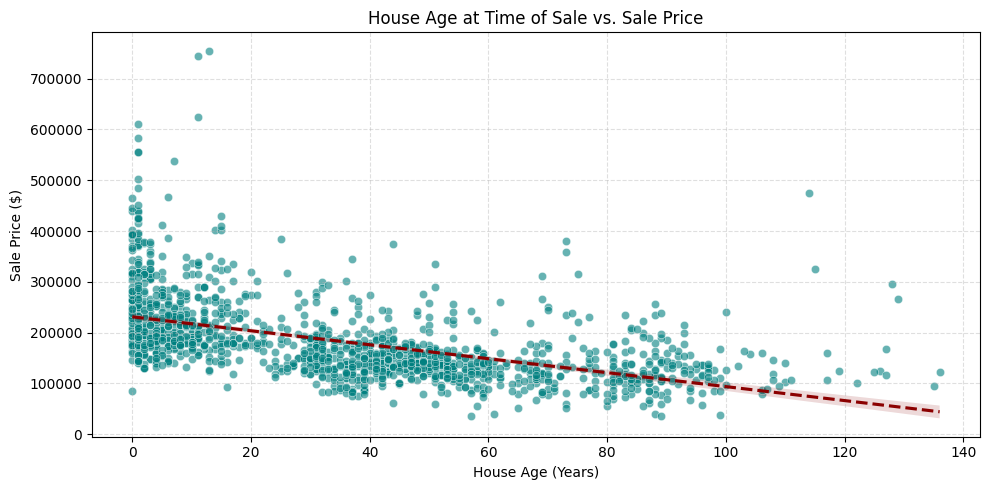


--- Interpretation (House Age) ---
House age has a negative linear correlation with price (r = -0.52). Newer homes cost more: median $225K for houses up to 5 years old vs $127K for houses older than 50.

Section 3.4 Summary: House Characteristics
• Primary Price Drivers: OverallQual (0.79) is the strongest, followed by GrLivArea (0.71) and GarageCars (0.64).
• Functional Features: Basements and multi-car garages (2-3 cars) provide essential baseline value premiums.
• Age Impact: House age generally depresses value, though room count shows diminishing returns beyond 4 bedrooms.


In [17]:
if 'House_Age' not in df.columns:
    df['House_Age'] = df['YrSold'] - df['YearBuilt']

if 'Has_Basement' not in df.columns:
    df['Has_Basement'] = df['TotalBsmtSF'].apply(
        lambda x: 'Has Basement' if x > 0 else 'No Basement'
    )

# ------------------------------------------------------------------------------
# 1. Number of Bedrooms vs Price
# ------------------------------------------------------------------------------
print("=" * 70)
print("1. Bedrooms Above Grade (BedroomAbvGr) vs SalePrice")
print("=" * 70)

bed_stats = (
    df.groupby('BedroomAbvGr')['SalePrice']
    .agg(Count='count', Median_Price='median', Mean_Price='mean')
    .reset_index()
)
display(bed_stats)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='BedroomAbvGr', y='SalePrice', palette='Blues')
plt.title('Sale Price by Number of Bedrooms Above Grade')
plt.xlabel('Bedrooms Above Grade')
plt.ylabel('Sale Price ($)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print("\n--- Interpretation (Bedrooms) ---")
print(
    "Median price is higher with 4 bedrooms than with 3, while the 5- and 6-bedroom groups are small (21 and 7 houses)."
)

# ------------------------------------------------------------------------------
# 2. Number of Bathrooms vs Price
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("2. Full Bathrooms (FullBath) vs SalePrice")
print("=" * 70)

bath_stats = (
    df.groupby('FullBath')['SalePrice']
    .agg(Count='count', Median_Price='median', Mean_Price='mean')
    .reset_index()
)
display(bath_stats)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='FullBath', y='SalePrice', palette='Greens')
plt.title('Sale Price by Number of Full Bathrooms')
plt.xlabel('Full Bathrooms')
plt.ylabel('Sale Price ($)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print("\n--- Interpretation (Bathrooms) ---")
print(
    "Full bathrooms act as a strong value multiplier. Homes with 3 full bathrooms command a significantly higher median price "
    "than 1 or 2 bathroom homes, reflecting luxury preferences."
)

# ------------------------------------------------------------------------------
# 3. OverallQual vs Price
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("3. Overall Quality (OverallQual) vs SalePrice")
print("=" * 70)

qual_stats = (
    df.groupby('OverallQual')['SalePrice']
    .agg(Count='count', Median_Price='median', Mean_Price='mean')
    .reset_index()
)
display(qual_stats)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x='OverallQual',
    y='SalePrice',
    palette='viridis',
    estimator=np.median,
    errorbar=None,
)
plt.title('Median Sale Price by Overall Quality Rating (1-10)')
plt.xlabel('Overall Quality Rating')
plt.ylabel('Sale Price ($)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print("\n--- Interpretation (Overall Quality) ---")
print(
    f"Strong positive relationship (r = {df['OverallQual'].corr(df['SalePrice']):.2f}): "
    "median price rises from $50,150 (quality 1) to $432,390 (quality 10)."
)

# ------------------------------------------------------------------------------
# 4. Garage Capacity vs Price
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("4. Garage Capacity (GarageCars) vs SalePrice")
print("=" * 70)

garage_stats = (
    df.groupby('GarageCars')['SalePrice']
    .agg(Count='count', Median_Price='median', Mean_Price='mean')
    .reset_index()
)
display(garage_stats)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='GarageCars', y='SalePrice', palette='Purples')
plt.title('Sale Price by Garage Capacity (Number of Cars)')
plt.xlabel('Garage Cars Capacity')
plt.ylabel('Sale Price ($)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print("\n--- Interpretation (Garage Capacity) ---")
print(
    "Garage capacity shows diminishing returns: moving from 0 to 2 cars yields a substantial price premium, "
    "and 3 cars reaches peak median price. However, 4-car garages plateau or slightly drop. "
    "Only 5 houses have 4-car garages, too few to draw a conclusion."
)

# ------------------------------------------------------------------------------
# 5. Basement vs No Basement
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("5. Basement Presence (Has_Basement) vs SalePrice")
print("=" * 70)

bsmt_stats = (
    df.groupby('Has_Basement')['SalePrice']
    .agg(Count='count', Median_Price='median', Mean_Price='mean')
    .reset_index()
)
display(bsmt_stats)

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x='Has_Basement',
    y='SalePrice',
    palette={'Has Basement': '#1f77b4', 'No Basement': '#d62728'},
)
plt.title('Sale Price Comparison: Has Basement vs No Basement')
plt.xlabel('Basement Status')
plt.ylabel('Sale Price ($)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

price_bsmt = bsmt_stats.loc[
    bsmt_stats['Has_Basement'] == 'Has Basement', 'Median_Price'
].values[0]
price_nobsmt = bsmt_stats.loc[
    bsmt_stats['Has_Basement'] == 'No Basement', 'Median_Price'
].values[0]
bsmt_premium = ((price_bsmt - price_nobsmt) / price_nobsmt) * 100

print("\n--- Interpretation (Basement) ---")
print(
    f"Homes with a basement achieve a median sale price of ${price_bsmt:,.2f} versus ${price_nobsmt:,.2f} for homes without one. "
    f"This represents a +{bsmt_premium:.1f}% baseline premium for basement foundation."
)

# ------------------------------------------------------------------------------
# 6. House Age vs Price
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("6. House Age at Sale (House_Age) vs SalePrice")
print("=" * 70)

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df, x='House_Age', y='SalePrice', alpha=0.6, color='teal'
)
sns.regplot(
    data=df,
    x='House_Age',
    y='SalePrice',
    scatter=False,
    color='darkred',
    line_kws={'linestyle': '--'},
)
plt.title('House Age at Time of Sale vs. Sale Price')
plt.xlabel('House Age (Years)')
plt.ylabel('Sale Price ($)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

age_corr = df['House_Age'].corr(df['SalePrice'])

print("\n--- Interpretation (House Age) ---")
print(
    f"House age has a negative linear correlation with price (r = {age_corr:.2f}). "
    "Newer homes cost more: median $225K for houses up to 5 years old vs $127K for houses older than 50."
)

df = df.drop(columns=['House_Age', 'Has_Basement'])

# ==============================================================================
# SECTION SUMMARY 3.4
# ==============================================================================
print("\n" + "=" * 70)
print("Section 3.4 Summary: House Characteristics")
print("=" * 70)
print(
    "• Primary Price Drivers: OverallQual (0.79) is the strongest, followed by GrLivArea (0.71) and GarageCars (0.64).\n"
    "• Functional Features: Basements and multi-car garages (2-3 cars) provide essential baseline value premiums.\n"
    "• Age Impact: House age generally depresses value, though room count shows diminishing returns beyond 4 bedrooms."
)

### 3.5 Additional insights (optional, encouraged)
- [ ] Extra question 1
- [ ] Extra question 2

C:\Users\elmoulll\AppData\Local\Temp\ipykernel_32728\3795450278.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


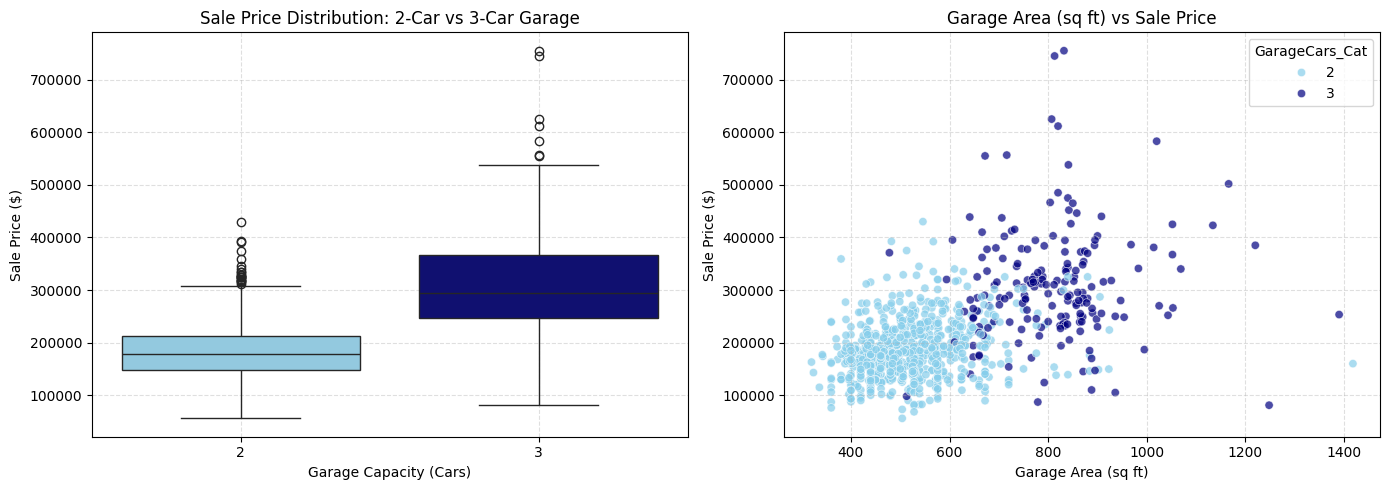

• 2-Car Garage Properties: Count =  824 | Median Price = $177,750.00 | Median Area = 506 sq ft
• 3-Car Garage Properties: Count =  181 | Median Price = $295,000.00 | Median Area = 818 sq ft
• Price Premium for 3-Car Garage: +$117,250.00 (+66.0%)
• Additional Garage Square Footage: +312 sq ft

--- Interpretation ---
Moving from a standard 2-car garage to a 3-car garage yields a substantial market premium. Properties with a 3-car capacity command a median price of $295,000.00 compared to $177,750.00 for 2-car garages, reflecting an absolute increase of +$117,250.00 (+66.0%). On average, 3-car garages add roughly 312 sq ft of usable floor space. 3-car houses are also larger (median 1,962 vs 1,502 sq ft) and higher quality (8 vs 6), so the 66% premium is not due to the garage alone.

Section 3.5 Summary: Garage Analysis
1. Substantial Garage Premium: Expanding garage capacity from 2 to 3 cars offers a major financial valuation boost of over +66.0% in median sale price.
2. Physical Scale Im

In [18]:
#is there a signficant price premium for homes with 3-car garages compared to 2-car garages, and how does garage area factor into this valuation?
garage_2_3 = df[df['GarageCars'].isin([2, 3])].copy()

# Ensure GarageCars is formatted cleanly as strings for categorical plotting
garage_2_3['GarageCars_Cat'] = garage_2_3['GarageCars'].astype(str)

garage_stats = (
    garage_2_3.groupby('GarageCars')['SalePrice']
    .agg(
        Count='count',
        Mean_Price='mean',
        Median_Price='median',
        Std_Dev='std',
    )
    .reset_index()
)

# Calculate Garage Area statistics
area_stats = (
    garage_2_3.groupby('GarageCars')['GarageArea']
    .agg(Mean_Area='mean', Median_Area='median')
    .reset_index()
)

# 3. Provide Suitable Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Boxplot showing Price Distribution for 2 vs 3 Cars
# Note: Palette keys are strings '2' and '3' to fix the ValueError
sns.boxplot(
    data=garage_2_3,
    x='GarageCars_Cat',
    y='SalePrice',
    palette={'2': 'skyblue', '3': 'navy'},
    ax=axes[0],
)
axes[0].set_title('Sale Price Distribution: 2-Car vs 3-Car Garage')
axes[0].set_xlabel('Garage Capacity (Cars)')
axes[0].set_ylabel('Sale Price ($)')
axes[0].grid(True, linestyle='--', alpha=0.4)

# Plot B: Scatter Plot of Garage Area vs Sale Price colored by Car Capacity
sns.scatterplot(
    data=garage_2_3,
    x='GarageArea',
    y='SalePrice',
    hue='GarageCars_Cat',
    palette={'2': 'skyblue', '3': 'navy'},
    alpha=0.7,
    ax=axes[1],
)
axes[1].set_title('Garage Area (sq ft) vs Sale Price')
axes[1].set_xlabel('Garage Area (sq ft)')
axes[1].set_ylabel('Sale Price ($)')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 4. Report the Result Using Actual Values
count_2 = garage_stats.loc[garage_stats['GarageCars'] == 2, 'Count'].values[0]
count_3 = garage_stats.loc[garage_stats['GarageCars'] == 3, 'Count'].values[0]

med_price_2 = garage_stats.loc[
    garage_stats['GarageCars'] == 2, 'Median_Price'
].values[0]
med_price_3 = garage_stats.loc[
    garage_stats['GarageCars'] == 3, 'Median_Price'
].values[0]

med_area_2 = area_stats.loc[
    area_stats['GarageCars'] == 2, 'Median_Area'
].values[0]
med_area_3 = area_stats.loc[
    area_stats['GarageCars'] == 3, 'Median_Area'
].values[0]

price_diff_median = med_price_3 - med_price_2
price_diff_pct = (price_diff_median / med_price_2) * 100
area_diff = med_area_3 - med_area_2

print(f"• 2-Car Garage Properties: Count = {count_2:4d} | Median Price = ${med_price_2:,.2f} | Median Area = {med_area_2:.0f} sq ft")
print(f"• 3-Car Garage Properties: Count = {count_3:4d} | Median Price = ${med_price_3:,.2f} | Median Area = {med_area_3:.0f} sq ft")
print(f"• Price Premium for 3-Car Garage: +${price_diff_median:,.2f} (+{price_diff_pct:.1f}%)")
print(f"• Additional Garage Square Footage: +{area_diff:.0f} sq ft")

# 5. Explain What the Result Means (Interpretation)
print("\n--- Interpretation ---")
print(
    f"Moving from a standard 2-car garage to a 3-car garage yields a substantial market premium. "
    f"Properties with a 3-car capacity command a median price of ${med_price_3:,.2f} compared to "
    f"${med_price_2:,.2f} for 2-car garages, reflecting an absolute increase of +${price_diff_median:,.2f} "
    f"(+{price_diff_pct:.1f}%). On average, 3-car garages add roughly {area_diff:.0f} sq ft of usable floor space. "
    "3-car houses are also larger (median 1,962 vs 1,502 sq ft) and higher quality (8 vs 6), so the 66% premium is not due to the garage alone."
)


# ==============================================================================
# SECTION SUMMARY
# ==============================================================================

print("\n" + "=" * 80)
print("Section 3.5 Summary: Garage Analysis")
print("=" * 80)
print(
    f"1. Substantial Garage Premium: Expanding garage capacity from 2 to 3 cars offers a major financial valuation boost "
    f"of over +{price_diff_pct:.1f}% in median sale price.\n"
    "2. Physical Scale Impact: 3-car houses are also larger (median 1,962 vs 1,502 sq ft) and higher quality (8 vs 6), "
    "so the 66% premium is not due to the garage alone."
)

#### 📝 Section Summary
Section 3 answered the project questions with numbers: SalePrice ranges from $34,900 to $755,000 (mean ≈ $180.9K, median $163K) and rises with living area (r = 0.71); the top 5% of houses (>= $326K) are larger, higher quality (92% have OverallQual >= 8), newer, and concentrated in NridgHt and NoRidge.
Neighborhood is a strong driver of price, explaining about 55% of its variance (average price from $98,576 in MeadowV to $335,295 in NoRidge), while the month of sale has almost no effect (less than 1% of variance; $171K in April vs $196K in September).
Among house characteristics, OverallQual (0.79) is the strongest driver, followed by GrLivArea (0.71) and GarageCars (0.64), and newer houses cost more (median $225K for houses up to 5 years old vs $127K for houses older than 50).
3-car garages have a 66% higher median price than 2-car garages, but those houses are also larger and higher quality, so the premium is not due to the garage alone.

# PART B: Preprocessing & Pipelines

## 4. Data Preprocessing

### 4.1 Preprocessing decisions (with justification)

| # | Aspect | Decision | Justification |
|---|--------|----------|---------------|
| 1 | Outliers | Remove houses `Id 524` and `Id 1299` before the split | Very large living area (4,676 and 5,642 sq ft) but low prices ($184,750 and $160,000). Both have `SaleCondition = Partial` (house not completed when assessed), so their price does not reflect their size and would mislead the model. Other IQR outliers are real expensive houses or large lots, so they are kept. |
| 2 | Duplicates | No action | No duplicate rows were found (checked excluding `Id`). |
| 3 | `NA` meaning "feature absent" | Replaced by a real category `'None'` (done in Section 1) | In 15 columns (basement, garage, pool, fence, alley...) `NA` means the house has no such feature, not a missing value. Imputing it would create false information (e.g. a house without a garage getting a "typical" garage). |
| 4 | Missing values: numerical | `SimpleImputer(strategy='median')` | `LotFrontage` is missing in 17.7% of houses and is skewed, so the median is more robust than the mean. `GarageYrBlt` (5.6%) and `MasVnrArea` (0.5%) are also imputed with the median. |
| 5 | Missing values: nominal | `SimpleImputer(strategy='most_frequent')` | Only `Electrical` is missing (1 house); the most frequent category (`SBrkr`) is a safe choice. |
| 6 | Missing values: ordinal | `SimpleImputer(strategy='most_frequent')` | No ordinal column has real missing values after step 3. The imputer is kept inside the pipeline as a safety net for unseen data. |
| 7 | Nominal encoding | `OneHotEncoder(handle_unknown='ignore')` | Categories have no natural order (e.g. `Neighborhood`, `MSZoning`). `ignore` prevents errors if a category appears only in validation/test. |
| 8 | Ordinal encoding | `OrdinalEncoder` with explicit category order from `ordinal_mapping` | The order carries information (`Po < Fa < TA < Gd < Ex`). `handle_unknown='use_encoded_value'` avoids errors on unseen values. |
| 9 | Skewed numerical features | Two transformations are applied to features with \|skew\| > 0.75 (list defined in 4.3, computed on the training set only, binary flags excluded) and compared: `log1p` and Yeo-Johnson. The choice for each model is made using validation performance in Section 6. | 21 features are right-skewed in the training set (`MiscVal` 21.0, `PoolArea` 13.3, `LotArea` 3.8, `GrLivArea` 1.06). Both transformations reduce skewness, which helps SVR as it is sensitive to feature distributions. `log1p` is simple and handles zeros; Yeo-Johnson learns a separate power parameter per feature (from the training set only) and reduced the mean \|skew\| more (2.43 vs 2.68; original 4.44). Features that are mostly zeros (e.g. `PoolArea`, `3SsnPorch`) remain skewed with both methods. |
| 10 | Scaler | `RobustScaler` | Real outliers remain after step 1 (expensive houses, large lots). `RobustScaler` uses the median and IQR, so it is not affected by them. Scaling is necessary because SVR is distance-based and very sensitive to feature scale. |
| 11 | Target | `np.log1p(SalePrice)` | Skewness drops from 1.88 to 0.12. Predictions are converted back with `np.expm1` so metrics can be reported in dollars. |
| 12 | Split | 70% train / 15% validation / 15% test, `random_state=42` | The test set is kept untouched until the final evaluation. A fixed seed makes results reproducible. |
| 13 | Feature engineering | 8 new features before the split: `TotalSF`, `TotalBath`, `HouseAge`, `RemodAge`, `Qual_x_Area`, `HasGarage`, `HasBasement`, `HasPool` | Related columns are combined into stronger signals (`Qual_x_Area` r = 0.87 and `TotalSF` r = 0.83 with SalePrice, higher than any original column). They are row-wise arithmetic, so nothing is learned from the data and there is no leakage. Their usefulness is tested in the ablation of Section 6.5. |

**Missing values strategy per group:** numerical → median, nominal → most frequent, ordinal → most frequent, "feature absent" → `'None'` category.

**All fitting (imputers, scaler, encoders) happens inside the Pipeline on the training data only, to avoid data leakage.**

### 4.2 Steps done BEFORE the split (no leakage risk)
- [ ] Remove duplicates (if any)
- [ ] Define feature lists
- [ ] Log transform of target

In [19]:
# 1) Remove the 2 suspicious outliers identified in Section 2.5
outlier_ids = [524, 1299]
print("Rows before:", len(df))
df_clean = df[~df['Id'].isin(outlier_ids)].copy()
print("Rows after: ", len(df_clean))

# 2) Feature engineering
# Only row-wise arithmetic: nothing is learned from the data, so doing it before the split causes no leakage
def add_features(d):
    d = d.copy()
    d['TotalSF']     = d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF']                                  # total living + basement area
    d['TotalBath']   = d['FullBath'] + 0.5 * d['HalfBath'] + d['BsmtFullBath'] + 0.5 * d['BsmtHalfBath'] # effective number of bathrooms
    d['HouseAge']    = d['YrSold'] - d['YearBuilt']                                                       # age at the time of sale
    d['RemodAge']    = d['YrSold'] - d['YearRemodAdd']                                                    # years since last remodel
    d['HasGarage']   = (d['GarageArea'] > 0).astype(int)
    d['HasBasement'] = (d['TotalBsmtSF'] > 0).astype(int)
    d['HasPool']     = (d['PoolArea'] > 0).astype(int)
    d['Qual_x_Area'] = d['OverallQual'] * d['GrLivArea']                                                  # quality x size
    return d

df_clean = add_features(df_clean)
new_features    = ['TotalSF', 'TotalBath', 'HouseAge', 'RemodAge', 'Qual_x_Area', 'HasGarage', 'HasBasement', 'HasPool']
binary_features = ['HasGarage', 'HasBasement', 'HasPool']
num_cols = [c for c in num_cols if c not in new_features] + new_features    # safe to re-run

print("\nCorrelation of the new features with SalePrice:")
display(df_clean[new_features + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')
        .sort_values(key=abs, ascending=False).round(2))

feature_cols = num_cols + nominal_cols + ordinal_cols
X = df_clean[feature_cols]
print("Features:", X.shape, "| numerical:", len(num_cols),
      "| nominal:", len(nominal_cols), "| ordinal:", len(ordinal_cols))

y = np.log1p(df_clean['SalePrice'])
print(f"Target skew: {df_clean['SalePrice'].skew():.2f} -> {y.skew():.2f} after log1p")

print("Columns that still have missing values (handled by the imputers in the pipeline):")
display(X.isna().sum()[lambda s: s > 0])

Rows before: 1460
Rows after:  1458

Correlation of the new features with SalePrice:


Qual_x_Area    0.87
TotalSF        0.83
TotalBath      0.64
HouseAge      -0.52
RemodAge      -0.51
HasGarage      0.24
HasBasement    0.15
HasPool        0.10
Name: SalePrice, dtype: float64

Features: (1458, 87) | numerical: 43 | nominal: 26 | ordinal: 18
Target skew: 1.88 -> 0.12 after log1p
Columns that still have missing values (handled by the imputers in the pipeline):


LotFrontage    259
MasVnrArea       8
GarageYrBlt     81
Electrical       1
dtype: int64

### 4.3 Train / Validation / Test split
- [ ] Split sizes and justification
- [ ] Fixed `random_state`
- [ ] Check target distribution across splits

In [20]:
price_bins = pd.qcut(y, q=5, labels=False)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=price_bins)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE,
    stratify=price_bins.loc[y_temp.index])

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

summary = pd.DataFrame({'train': y_train.describe(),
                        'validation': y_val.describe(),
                        'test': y_test.describe()}).round(3)
display(summary.loc[['count', 'mean', 'std', 'min', '50%', 'max']])

train_skew = X_train[num_cols].skew()
skewed_cols = [c for c in train_skew[train_skew.abs() > 0.75].sort_values(ascending=False).index
               if c not in binary_features]
print(f"{len(skewed_cols)} skewed features (|skew| > 0.75):")
display(train_skew[skewed_cols].round(2))

# log1p needs non-negative values
print("Features with negative values:", [c for c in skewed_cols if X_train[c].min() < 0])

Train: (1020, 87) | Validation: (219, 87) | Test: (219, 87)


,train,validation,test
count,1020.000,219.000,219.000
mean,12.027,12.027,12.008
std,0.406,0.390,0.380
min,10.460,10.597,10.543
50%,12.001,12.008,12.008
max,13.534,13.196,13.230


21 skewed features (|skew| > 0.75):


MiscVal          21.02
PoolArea         13.31
3SsnPorch         9.89
LowQualFinSF      9.34
KitchenAbvGr      4.57
BsmtHalfBath      4.20
BsmtFinSF2        4.10
ScreenPorch       4.09
LotArea           3.82
EnclosedPorch     3.15
MasVnrArea        2.85
OpenPorchSF       2.46
LotFrontage       1.84
Qual_x_Area       1.61
WoodDeckSF        1.58
GrLivArea         1.06
1stFlrSF          0.96
BsmtUnfSF         0.91
TotalSF           0.88
BsmtFinSF1        0.82
2ndFlrSF          0.81
dtype: float64

Features with negative values: []


#### 📝 Section Summary
Two suspicious outliers (Id 524 and 1299, large houses sold as `Partial`) were removed, leaving 1,458 houses. Eight features were engineered (e.g. `TotalSF`, `TotalBath`, `HouseAge`, `Qual_x_Area`), giving 87 features (43 numerical, 26 nominal, 18 ordinal); `Qual_x_Area` (r = 0.87) and `TotalSF` (r = 0.83) are the features most correlated with price. The target was transformed with `log1p`, which reduced its skewness from 1.88 to 0.12. The data was split into 70% train (1,020), 15% validation (219) and 15% test (219) with `random_state=42`, stratified by price bins so the target distribution is almost identical across the three sets. 21 numerical features are skewed (|skew| > 0.75, computed on the training set only, binary flags excluded) and will be transformed inside the pipeline. All imputing, scaling and encoding will be fitted on the training data only to avoid data leakage.

## 5. Pipelines & ColumnTransformer

### 5.1 Pipeline 1: Numerical features
- [ ] Imputation
- [ ] Transformation (when required)
- [ ] Scaling

log1p: train (1020, 43) | val (219, 43) | NaN: 0, 0
yeo_johnson: train (1020, 43) | val (219, 43) | NaN: 0, 0


,original,log1p,yeo_johnson
MiscVal,21.02,5.60,5.38
PoolArea,13.31,12.95,12.94
3SsnPorch,9.89,7.70,7.56
LowQualFinSF,9.34,7.77,7.56
KitchenAbvGr,4.57,4.45,0.00
BsmtHalfBath,4.20,4.06,4.00
BsmtFinSF2,4.10,2.42,2.33
ScreenPorch,4.09,3.03,3.00
LotArea,3.82,-0.71,0.11
EnclosedPorch,3.15,2.02,1.95


Features where each method gives the lowest |skew|: {'yeo_johnson': 20, 'log1p': 1}


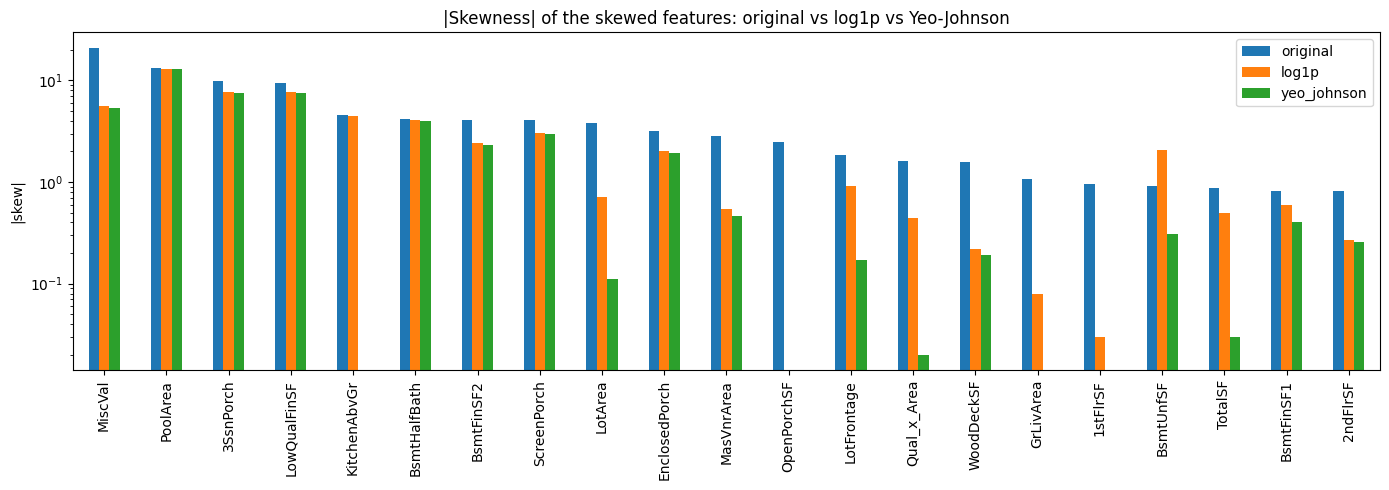

In [21]:
# Pipeline 1: numerical features. Two versions, to compare log1p vs Yeo-Johnson
skew_idx = [num_cols.index(c) for c in skewed_cols]

# Version A: log1p on the skewed features
def log_skewed(A):
    A = np.array(A, dtype=float, copy=True)
    A[:, skew_idx] = np.log1p(A[:, skew_idx])
    return A

num_pipeline_log = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(log_skewed, feature_names_out='one-to-one')),
    ('scaler', RobustScaler())
])

# Version B: Yeo-Johnson on the skewed features (lambda learned from the training set)
num_pipeline_yj = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('yeo_johnson', ColumnTransformer(
        [('yj', PowerTransformer(method='yeo-johnson', standardize=False), skew_idx)],
        remainder='passthrough')),
    ('scaler', RobustScaler())
])

num_pipelines = {'log1p': num_pipeline_log, 'yeo_johnson': num_pipeline_yj}
num_pipeline = num_pipeline_log          # default version used by the rest of the notebook

# Fit both on train only and transform
results = {}
for name, pipe in num_pipelines.items():
    arr = pipe.fit_transform(X_train[num_cols])
    val = pipe.transform(X_val[num_cols])
    cols = [c.split('__')[-1] for c in pipe.get_feature_names_out(num_cols)]
    results[name] = pd.DataFrame(arr, columns=cols)
    print(f"{name}: train {arr.shape} | val {val.shape} | NaN: {np.isnan(arr).sum()}, {np.isnan(val).sum()}")

# Comparison of skewness
comparison = pd.DataFrame({
    'original': X_train[skewed_cols].skew(),
    'log1p': results['log1p'][skewed_cols].skew(),
    'yeo_johnson': results['yeo_johnson'][skewed_cols].skew()
}).round(2)
comparison.loc['MEAN |skew|'] = comparison.abs().mean().round(2)
display(comparison)

wins = comparison.drop(index='MEAN |skew|')[['log1p', 'yeo_johnson']].abs().idxmin(axis=1).value_counts()
print("Features where each method gives the lowest |skew|:", wins.to_dict())

# Bar chart
comparison.drop(index='MEAN |skew|').abs().plot(kind='bar', figsize=(14, 5))
plt.title('|Skewness| of the skewed features: original vs log1p vs Yeo-Johnson')
plt.ylabel('|skew|'); plt.yscale('log'); plt.tight_layout(); plt.show()


### 5.2 Pipeline 2: Nominal categorical features
- [ ] Imputation
- [ ] One-Hot Encoding

In [22]:
# Pipeline 2: nominal categorical features  (imputer -> One-Hot Encoding)
nominal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Quick test (fit on train only)
Xt_nom = nominal_pipeline.fit_transform(X_train[nominal_cols])
Xv_nom = nominal_pipeline.transform(X_val[nominal_cols])
Xs_nom = nominal_pipeline.transform(X_test[nominal_cols])
print("Train:", Xt_nom.shape, "| Validation:", Xv_nom.shape, "| Test:", Xs_nom.shape)
print("NaN left:", np.isnan(Xt_nom).sum())
print("Nominal columns:", len(nominal_cols), "->", Xt_nom.shape[1], "one-hot columns")

# Categories that appear in validation/test but never in train (handled by handle_unknown='ignore')
for name, Xo in [('validation', X_val), ('test', X_test)]:
    for c in nominal_cols:
        unseen = set(Xo[c].unique()) - set(X_train[c].unique())
        if unseen:
            print(f"{name}: '{c}' has unseen categories {unseen}")

Train: (1020, 186) | Validation: (219, 186) | Test: (219, 186)
NaN left: 0
Nominal columns: 26 -> 186 one-hot columns
validation: 'RoofMatl' has unseen categories {'Metal'}
validation: 'Heating' has unseen categories {'OthW'}
test: 'RoofMatl' has unseen categories {'Roll'}
test: 'Exterior1st' has unseen categories {'ImStucc'}


### 5.3 Pipeline 3: Ordinal categorical features
- [ ] Imputation
- [ ] Ordinal Encoding (explicit category order)

In [23]:
# Pipeline 3: ordinal categorical features  (imputer -> Ordinal Encoding with explicit order)
ordinal_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(
        categories=[ordinal_mapping[c] for c in ordinal_cols],   # same order as ordinal_cols
        handle_unknown='use_encoded_value',
        unknown_value=-1))
])

# Quick test (fit on train only)
Xt_ord = ordinal_pipeline.fit_transform(X_train[ordinal_cols])
Xv_ord = ordinal_pipeline.transform(X_val[ordinal_cols])
Xs_ord = ordinal_pipeline.transform(X_test[ordinal_cols])
print("Train:", Xt_ord.shape, "| Validation:", Xv_ord.shape, "| Test:", Xs_ord.shape)
print("NaN left:", np.isnan(Xt_ord).sum())
print("Minimum encoded value (train, val, test):", Xt_ord.min(), Xv_ord.min(), Xs_ord.min(),
      "  (-1 would mean an unseen category)")

# Check the encoding on a few houses
encoded = pd.DataFrame(Xt_ord, columns=ordinal_cols, index=X_train.index)
check_cols = ['ExterQual', 'BsmtQual', 'GarageFinish']
display(pd.concat([X_train[check_cols].add_suffix(' (original)'),
                   encoded[check_cols].add_suffix(' (encoded)')], axis=1).head(5))

Train: (1020, 18) | Validation: (219, 18) | Test: (219, 18)
NaN left: 0
Minimum encoded value (train, val, test): 0.0 0.0 0.0   (-1 would mean an unseen category)


,ExterQual (original),BsmtQual (original),GarageFinish (original),ExterQual (encoded),BsmtQual (encoded),GarageFinish (encoded)
328,TA,TA,Unf,2.0,3.0,1.0
786,TA,Fa,Unf,2.0,2.0,1.0
1134,TA,Gd,Fin,2.0,4.0,3.0
815,TA,Gd,RFn,2.0,4.0,2.0
763,Gd,Gd,RFn,3.0,4.0,2.0


### 5.4 ColumnTransformer
- [ ] Combine the three pipelines
- [ ] Sanity check: transformed shape, no NaNs

In [43]:
# ColumnTransformer: combine the three pipelines (one version per numerical-transform choice)
def build_preprocessor(num_pipe):
    return ColumnTransformer(transformers=[
        ('num',     num_pipe,          num_cols),
        ('nominal', nominal_pipeline,  nominal_cols),
        ('ordinal', ordinal_pipeline,  ordinal_cols)
    ])

preprocessor_log = build_preprocessor(num_pipeline_log)    # log1p version
preprocessor_yj  = build_preprocessor(num_pipeline_yj)     # Yeo-Johnson version
preprocessor = preprocessor_log                            # default name used by the modelling part

# Sanity check: fit on train only, transform validation and test
for name, prep in [('log1p', preprocessor_log), ('yeo_johnson', preprocessor_yj)]:
    Xt = prep.fit_transform(X_train)
    Xv = prep.transform(X_val)
    Xs = prep.transform(X_test)
    feature_names = prep.get_feature_names_out()
    print(f"[{name}] train {Xt.shape} | val {Xv.shape} | test {Xs.shape}")
    print(f"[{name}] NaN left (train, val, test): {np.isnan(Xt).sum()}, {np.isnan(Xv).sum()}, {np.isnan(Xs).sum()}")
    print(f"[{name}] features: {len(feature_names)} (unique names: {len(set(feature_names))})")

print("\nColumns by group (43 numerical + 186 one-hot + 18 ordinal):")
print(pd.Series([n.split('__')[0] for n in preprocessor_log.get_feature_names_out()]).value_counts())

[log1p] train (1020, 247) | val (219, 247) | test (219, 247)
[log1p] NaN left (train, val, test): 0, 0, 0
[log1p] features: 247 (unique names: 247)
[yeo_johnson] train (1020, 247) | val (219, 247) | test (219, 247)
[yeo_johnson] NaN left (train, val, test): 0, 0, 0
[yeo_johnson] features: 247 (unique names: 247)

Columns by group (43 numerical + 186 one-hot + 18 ordinal):
nominal    186
num         43
ordinal     18
Name: count, dtype: int64


**Note:** all preprocessing must stay inside the pipeline (fit on train only) to avoid data leakage.

#### 📝 Section Summary
Three preprocessing pipelines were built and combined with a `ColumnTransformer`: (1) numerical (median imputation → transformation of the 21 skewed features → `RobustScaler`; the 43 numerical columns include the engineered features, and binary flags only pass through the scaler), (2) nominal (most-frequent imputation → One-Hot Encoding, 26 columns expanded to 186), and (3) ordinal (most-frequent imputation → Ordinal Encoding with an explicit order for 18 columns). Two versions of the numerical pipeline were created, using `log1p` and Yeo-Johnson, so they can be compared on model performance later. Yeo-Johnson gave the lowest skewness in 20 of the 21 features. Features that are mostly zeros (e.g. `PoolArea`, `3SsnPorch`) remain skewed with both methods. The final preprocessor outputs 247 features with no missing values, and it is fitted on the training set only. A few rare categories that appear only in validation/test (e.g. `Metal` roof) are encoded as all zeros thanks to `handle_unknown='ignore'`.

# PART C: Modeling & Evaluation

## 6. Model Development

### 6.1 Evaluation helper
- [ ] MAE, MSE, RMSE, R² (note: target is on log scale, state whether metrics are reported on log or original scale)

In [25]:
# The main metrics (MAE, MSE, RMSE, R²) are reported in dollars; RMSE and R² on the log scale are kept as extra columns.
def evaluate_model(model, X, y_log, model_name, split):
    pred_log = model.predict(X)
    y_true, y_pred = np.expm1(y_log), np.expm1(pred_log)
    mse = mean_squared_error(y_true, y_pred)
    return {
        'Model': model_name, 'Split': split,
        'MAE ($)': mean_absolute_error(y_true, y_pred),
        'MSE': mse,
        'RMSE ($)': np.sqrt(mse),
        'R²': r2_score(y_true, y_pred),
        'RMSE (log)': np.sqrt(mean_squared_error(y_log, pred_log)),
        'R² (log)': r2_score(y_log, pred_log),
    }

results_list = []      # every evaluation is stored here, to build the comparison table in Section 8

def evaluate_train_val(model, model_name):
    """Evaluate on train and validation only. The test set is NOT touched here."""
    rows = [evaluate_model(model, X_train, y_train, model_name, 'train'),
            evaluate_model(model, X_val,   y_val,   model_name, 'validation')]
    results_list.extend(rows)
    return pd.DataFrame(rows).set_index(['Model', 'Split']).round(3)

def evaluate_test(model, model_name):
    """Use ONLY in Section 8, once, after the hyperparameters are fixed."""
    row = evaluate_model(model, X_test, y_test, model_name, 'test')
    results_list.append(row)
    return pd.DataFrame([row]).set_index(['Model', 'Split']).round(3)

def results_table():
    """All results collected so far (re-running a cell keeps only the latest result)."""
    return (pd.DataFrame(results_list)
              .drop_duplicates(['Model', 'Split'], keep='last')
              .set_index(['Model', 'Split']).round(3))

# Baseline: always predicts the median price. Any real model must beat this.
baseline = Pipeline([('prep', preprocessor), ('model', DummyRegressor(strategy='median'))])
baseline.fit(X_train, y_train)
display(evaluate_train_val(baseline, 'Baseline (median)'))

MAE ($)           MSE   RMSE ($)     R²  \
Model             Split                                                   
Baseline (median) train       56748.952  7.174940e+09  84705.019 -0.053   
                  validation  53943.123  5.961552e+09  77211.090 -0.055   

                              RMSE (log)  R² (log)  
Model             Split                             
Baseline (median) train            0.407    -0.004  
                  validation       0.390    -0.005

### 6.2 Model 1: Support Vector Regression (SVR)
- [ ] Preprocessing → SVR pipeline
- [ ] Baseline performance

In [26]:
# 6.2 Model 1: Support Vector Regression (default hyperparameters)
# Full pipeline = preprocessing -> SVR. Two versions, one per numerical transformation.
svr_log = Pipeline(steps=[('prep', preprocessor_log), ('model', SVR())])
svr_yj  = Pipeline(steps=[('prep', preprocessor_yj),  ('model', SVR())])

svr_log.fit(X_train, y_train)
svr_yj.fit(X_train, y_train)

display(pd.concat([
    evaluate_train_val(svr_log, 'SVR default (log1p)'),
    evaluate_train_val(svr_yj,  'SVR default (Yeo-Johnson)')
]))

# The version used from now on (change this line if Yeo-Johnson turns out better in Section 8)
svr_pipeline = svr_log

MAE ($)           MSE   RMSE ($)  \
Model                     Split                                            
SVR default (log1p)       train       12253.176  3.007255e+08  17341.440   
                          validation  13268.868  4.046770e+08  20116.585   
SVR default (Yeo-Johnson) train       12122.577  3.083840e+08  17560.866   
                          validation  13372.249  4.179182e+08  20443.047   

                                         R²  RMSE (log)  R² (log)  
Model                     Split                                    
SVR default (log1p)       train       0.956       0.088     0.953  
                          validation  0.928       0.118     0.907  
SVR default (Yeo-Johnson) train       0.955       0.089     0.952  
                          validation  0.926       0.119     0.906

### 6.3 Model 2: K-Nearest Neighbors (KNN) Regression
- [ ] Preprocessing → KNN pipeline
- [ ] Baseline performance

In [27]:
# 6.3 Model 2: K-Nearest Neighbors Regression (default hyperparameters)
knn_log = Pipeline(steps=[('prep', preprocessor_log), ('model', KNeighborsRegressor())])
knn_yj  = Pipeline(steps=[('prep', preprocessor_yj),  ('model', KNeighborsRegressor())])

knn_log.fit(X_train, y_train)
knn_yj.fit(X_train, y_train)

display(pd.concat([
    evaluate_train_val(knn_log, 'KNN default (log1p)'),
    evaluate_train_val(knn_yj,  'KNN default (Yeo-Johnson)')
]))

knn_pipeline = knn_yj

MAE ($)           MSE   RMSE ($)  \
Model                     Split                                            
KNN default (log1p)       train       18994.618  9.486019e+08  30799.382   
                          validation  19181.773  9.892061e+08  31451.647   
KNN default (Yeo-Johnson) train       17231.702  7.508390e+08  27401.442   
                          validation  17996.066  7.855107e+08  28026.964   

                                         R²  RMSE (log)  R² (log)  
Model                     Split                                    
KNN default (log1p)       train       0.861       0.140     0.881  
                          validation  0.825       0.161     0.829  
KNN default (Yeo-Johnson) train       0.890       0.127     0.903  
                          validation  0.861       0.155     0.842

### 6.4 Additional models
- [ ] Ridge Regression
- [ ] Lasso Regression
- [ ] ElasticNet (combination of Ridge and Lasso)

In [28]:
# 6.4 Additional models: regularized linear models (stable even with correlated / redundant features)
ridge_log = Pipeline(steps=[('prep', preprocessor_log), ('model', Ridge())])
ridge_yj  = Pipeline(steps=[('prep', preprocessor_yj),  ('model', Ridge())])
lasso_log = Pipeline(steps=[('prep', preprocessor_log), ('model', Lasso(alpha=0.001, max_iter=10000))])
lasso_yj  = Pipeline(steps=[('prep', preprocessor_yj),  ('model', Lasso(alpha=0.001, max_iter=10000))])

for pipe in (ridge_log, ridge_yj, lasso_log, lasso_yj):
    pipe.fit(X_train, y_train)

display(pd.concat([
    evaluate_train_val(ridge_log, 'Ridge default (log1p)'),
    evaluate_train_val(ridge_yj,  'Ridge default (Yeo-Johnson)'),
    evaluate_train_val(lasso_log, 'Lasso baseline (log1p)'),
    evaluate_train_val(lasso_yj,  'Lasso baseline (Yeo-Johnson)')
]))

ridge_pipeline = ridge_yj
lasso_pipeline = lasso_yj

MAE ($)           MSE   RMSE ($)  \
Model                        Split                                            
Ridge default (log1p)        train       11623.146  3.166376e+08  17794.314   
                             validation  14460.757  4.292104e+08  20717.393   
Ridge default (Yeo-Johnson)  train       11423.529  3.020870e+08  17380.650   
                             validation  13893.320  3.974116e+08  19935.186   
Lasso baseline (log1p)       train       13462.837  4.427257e+08  21041.048   
                             validation  13699.749  4.082953e+08  20206.319   
Lasso baseline (Yeo-Johnson) train       13293.208  4.263759e+08  20648.872   
                             validation  13374.333  3.851649e+08  19625.617   

                                            R²  RMSE (log)  R² (log)  
Model                        Split                                    
Ridge default (log1p)        train       0.954       0.087     0.954  
                             validation  0.924       0.123     0.900  
Ridge default (Yeo-Johnson)  train       0.956       0.087     0.955  
                             validation  0.930       0.122     0.902  
Lasso baseline (log1p)       train       0.935       0.100     0.939  
                             validation  0.928       0.116     0.911  
Lasso baseline (Yeo-Johnson) train       0.937       0.100     0.940  
                             validation  0.932       0.116     0.911

In [29]:
# 6.4 (continued): ElasticNet = L1 (Lasso) + L2 (Ridge) penalties in one model
elastic_log = Pipeline(steps=[('prep', preprocessor_log),
                              ('model', ElasticNet(alpha=0.001))])
elastic_yj  = Pipeline(steps=[('prep', preprocessor_yj),
                              ('model', ElasticNet(alpha=0.001))])

for pipe in (elastic_log, elastic_yj):
    pipe.fit(X_train, y_train)

display(pd.concat([
    evaluate_train_val(elastic_log, 'ElasticNet baseline (log1p)'),
    evaluate_train_val(elastic_yj,  'ElasticNet baseline (Yeo-Johnson)')
]))

elastic_pipeline = elastic_yj

MAE ($)           MSE  \
Model                             Split                                 
ElasticNet baseline (log1p)       train       12779.668  3.922811e+08   
                                  validation  13909.318  3.998382e+08   
ElasticNet baseline (Yeo-Johnson) train       12612.004  3.784214e+08   
                                  validation  13360.319  3.668090e+08   

                                               RMSE ($)     R²  RMSE (log)  \
Model                             Split                                      
ElasticNet baseline (log1p)       train       19806.088  0.942       0.096   
                                  validation  19995.954  0.929       0.116   
ElasticNet baseline (Yeo-Johnson) train       19453.056  0.944       0.095   
                                  validation  19152.259  0.935       0.115   

                                              R² (log)  
Model                             Split                 
ElasticNet baseline (log1p)       train          0.944  
                                  validation     0.911  
ElasticNet baseline (Yeo-Johnson) train          0.945  
                                  validation     0.912

In [30]:
# 6.5 Ablation: effect of the engineered features (default hyperparameters, Yeo-Johnson)
def make_preprocessor(num_list):
    """Same 3 pipelines as Section 5, but with a custom list of numerical columns."""
    skewed = [c for c in skewed_cols if c in num_list]
    idx = [num_list.index(c) for c in skewed]
    num_pipe = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('yeo_johnson', ColumnTransformer(
            [('yj', PowerTransformer(method='yeo-johnson', standardize=False), idx)],
            remainder='passthrough')),
        ('scaler', RobustScaler())
    ])
    return ColumnTransformer(transformers=[
        ('num',     num_pipe,          num_list),
        ('nominal', nominal_pipeline,  nominal_cols),
        ('ordinal', ordinal_pipeline,  ordinal_cols)
    ])

source_cols = ['TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'FullBath', 'HalfBath',
               'BsmtFullBath', 'BsmtHalfBath', 'YearBuilt', 'YearRemodAdd']

num_variants = {
    'A: original only':              [c for c in num_cols if c not in new_features],
    'B: original + engineered':      num_cols,
    'C: engineered replace sources': [c for c in num_cols if c not in source_cols],
}
models = {'SVR': SVR(), 'KNN': KNeighborsRegressor(), 'Ridge': Ridge(),
          'Lasso (alpha=0.001)': Lasso(alpha=0.001, max_iter=10000),
          'ElasticNet (alpha=0.001)': ElasticNet(alpha=0.001)}

ablation_rows = []
for variant, cols in num_variants.items():
    for model_name, model in models.items():
        pipe = Pipeline([('prep', make_preprocessor(cols)), ('model', clone(model))])
        pipe.fit(X_train, y_train)
        ablation_rows.append(evaluate_model(pipe, X_val, y_val, f'{model_name} | {variant}', 'validation'))

ablation = pd.DataFrame(ablation_rows).set_index('Model')[['MAE ($)', 'RMSE ($)', 'R²']].round(3)
display(ablation)

,MAE ($),RMSE ($),R²
Model,,,
SVR | A: original only,13763.240,20824.269,0.923
KNN | A: original only,18933.532,30482.588,0.836
Ridge | A: original only,13940.731,19964.531,0.929
Lasso (alpha=0.001) | A: original only,13530.061,19965.751,0.929
ElasticNet (alpha=0.001) | A: original only,13601.628,19577.122,0.932
SVR | B: original + engineered,13372.249,20443.047,0.926
KNN | B: original + engineered,17996.066,28026.964,0.861
Ridge | B: original + engineered,13893.320,19935.186,0.930
Lasso (alpha=0.001) | B: original + engineered,13374.333,19625.617,0.932


#### 📝 Section Summary
Five regression models were trained with default settings as full pipelines (preprocessing → model): SVR, KNN, Ridge, Lasso and ElasticNet (`alpha=0.001`, `l1_ratio=0.5`), plus a median-price baseline (validation R² = -0.055, RMSE ≈ $77.2K). Each model was fitted with both the log1p and the Yeo-Johnson versions of the numerical transformation and evaluated on train and validation only; the test set was not touched. Yeo-Johnson was kept for KNN, Ridge, Lasso and ElasticNet and log1p for SVR, since the differences between the two transformations were small. SVR, Ridge, Lasso and ElasticNet performed almost the same (validation R² ≈ 0.924-0.935, RMSE ≈ $19.2K-$20.7K), while KNN was clearly weaker (R² = 0.825 with log1p, 0.861 with Yeo-Johnson). SVR, KNN and Ridge had the largest train–validation gaps (R² ≈ 0.03), while Lasso and ElasticNet had the smallest (about 0.01 or less). Linear Regression was removed because the engineered features are exact linear combinations of other features, which made its predictions unstable. An ablation study (Section 6.5) showed that the engineered features improved KNN the most (R² 0.836 → 0.861) and the other models slightly, while replacing the original features with them gave no extra benefit, so the original + engineered set was kept.

## 7. Hyperparameter Tuning
### 7.1 SVR tuning
### 7.2 Explanation of tuned hyperparameters
### 7.3 SVR tuning with Optuna (extra experiment)
### 7.4 Model 2 tuning: KNN
### 7.5 Additional tuning: Ridge, Lasso and ElasticNet

In [31]:
# 7.1 SVR tuning: GridSearchCV on the training set only (5-fold CV, fixed random_state)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def run_grid(pipeline, param_grid, name):
    gs = GridSearchCV(pipeline, param_grid, cv=cv,
                      scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train)
    print(f"{name}: best params = {gs.best_params_}")
    print(f"{name}: best CV RMSE (log scale) = {-gs.best_score_:.4f}")
    return gs

Cs = [1, 3, 10, 30, 100]
svr_grid = [
    {'model__kernel': ['rbf'],  'model__C': Cs,
     'model__gamma': ['scale', 'auto', 0.0001, 0.0003, 0.001, 0.003],
     'model__epsilon': [0.01, 0.05, 0.1]},
    {'model__kernel': ['poly'], 'model__C': Cs,
     'model__gamma': ['scale', 'auto', 0.0003, 0.001, 0.003],
     'model__degree': [2, 3],
     'model__epsilon': [0.01, 0.05, 0.1]},
]

svr_gs = run_grid(svr_pipeline, svr_grid, 'SVR')
display(evaluate_train_val(svr_gs.best_estimator_, 'SVR tuned (log1p)'))

SVR: best params = {'model__C': 100, 'model__epsilon': 0.05, 'model__gamma': 0.0003, 'model__kernel': 'rbf'}
SVR: best CV RMSE (log scale) = 0.1083


MAE ($)           MSE   RMSE ($)     R²  \
Model             Split                                                   
SVR tuned (log1p) train        9688.338  2.203726e+08  14844.953  0.968   
                  validation  12732.411  3.270632e+08  18084.889  0.942   

                              RMSE (log)  R² (log)  
Model             Split                             
SVR tuned (log1p) train            0.078     0.963  
                  validation       0.120     0.905

In [32]:
cv_res = pd.DataFrame(svr_gs.cv_results_)
cv_res['CV RMSE (log)'] = -cv_res['mean_test_score']
for p in ['kernel', 'C', 'gamma', 'epsilon', 'degree']:
    display(cv_res.groupby(f'param_model__{p}', dropna=False)['CV RMSE (log)']
            .min().round(4).to_frame(f'best CV RMSE by {p}'))

,best CV RMSE by kernel
param_model__kernel,
poly,0.1099
rbf,0.1083


,best CV RMSE by C
param_model__C,
1,0.1099
3,0.1098
10,0.1084
30,0.1085
100,0.1083


,best CV RMSE by gamma
param_model__gamma,
0.0001,0.1091
0.0003,0.1083
0.001,0.1084
0.003,0.1099
auto,0.1103
scale,0.1099


,best CV RMSE by epsilon
param_model__epsilon,
0.01,0.1087
0.05,0.1083
0.10,0.1097


,best CV RMSE by degree
param_model__degree,
NaN,0.1083
2.0,0.1099
3.0,0.1142


### 7.2 Explanation of tuned hyperparameters

The table shows the best CV RMSE (log scale, lower is better) reached with each value of a hyperparameter, over all combinations of the others.

| Hyperparameter | Best CV RMSE by value |
|---|---|
| `kernel` | rbf **0.1083**, poly 0.1099 |
| `C` | 1: 0.1099, 3: 0.1098, 10: 0.1084, 30: 0.1085, **100: 0.1083** |
| `gamma` | 0.0001: 0.1091, **0.0003: 0.1083**, 0.001: 0.1084, 0.003: 0.1099, scale: 0.1099, auto: 0.1103 |
| `epsilon` | 0.01: 0.1087, **0.05: 0.1083**, 0.1: 0.1097 |
| `degree` (poly only) | 2: 0.1099, 3: 0.1142 |

- **`C`** controls the trade-off between fitting the training data and allowing errors: a larger `C` penalizes errors more and gives a more complex model. Performance improved clearly from `C=1-3` (0.1098-0.1099, underfitting) to `C=10` (0.1084) and then stayed flat up to `C=100` (0.1083), so any value between 10 and 100 works and the choice is not critical.
- **`kernel`** defines how relationships are learned: RBF captures non-linear relationships, polynomial uses polynomial terms. RBF was better (0.1083 vs 0.1099).
- **`gamma`** controls how far the influence of a single training point reaches: a higher value gives a more complex, wiggly model, a lower value gives smoother predictions. The best values were small (0.0003-0.001), clearly better than the default `scale` (0.1099) and `auto` (0.1103); both the smaller (0.0001) and the larger (0.003) values were worse, so the optimum lies inside the grid.
- **`epsilon`** is the width of the tube around the prediction inside which errors are ignored. Since the target is on a log scale, the default `0.1` means ignoring errors of about 10% of the price, which is too tolerant (0.1097). `0.05` was the best (0.1083) and `0.01` was slightly worse (0.1087).
- **`degree`** is only used by the polynomial kernel. `degree=2` (0.1099) was clearly better than `degree=3` (0.1142), because a higher degree adds flexibility that mostly fits noise. Its NaN row in the table corresponds to the RBF kernel, which ignores it.

The final SVR is a smooth RBF model: `kernel='rbf'`, `C=100`, `gamma=0.0003`, `epsilon=0.05`. Tuning `gamma` and `epsilon` mattered most: the best `gamma` (0.0003) is smaller than the default `scale`, and the best `epsilon` (0.05) is smaller than the default 0.1.

**Limitation of GridSearchCV.** It only returns the best combination inside the grid we defined, not the global optimum. We saw this in practice: in a first, narrower grid the best `gamma` was on the edge (0.001, CV RMSE 0.1110); after extending the grid the best value moved to 0.0003 and the CV RMSE improved to 0.1083. Tools that search continuous ranges can refine the settings further: this is tested with Optuna in Section 7.3, which found a slightly better configuration (CV RMSE 0.1064 vs 0.1083).

Optuna best params: {'numeric_transform': 'yeo_johnson', 'C': 55.57112988478942, 'gamma': 0.0002840334994649999, 'epsilon': 0.02744434949318132}
Optuna best CV RMSE (log scale) = 0.1064   (GridSearchCV: 0.1083)


MAE ($)           MSE   RMSE ($)     R²  \
Model            Split                                                   
SVR Optuna (TPE) train        9861.637  2.675311e+08  16356.379  0.961   
                 validation  12085.832  3.189812e+08  17860.044  0.944   

                             RMSE (log)  R² (log)  
Model            Split                             
SVR Optuna (TPE) train            0.086     0.955  
                 validation       0.115     0.912

,CV RMSE (log),Val MAE ($),Val RMSE ($),Val R²
GridSearchCV,0.1083,12732.411,18084.889,0.942
Optuna (TPE),0.1064,12085.832,17860.044,0.944


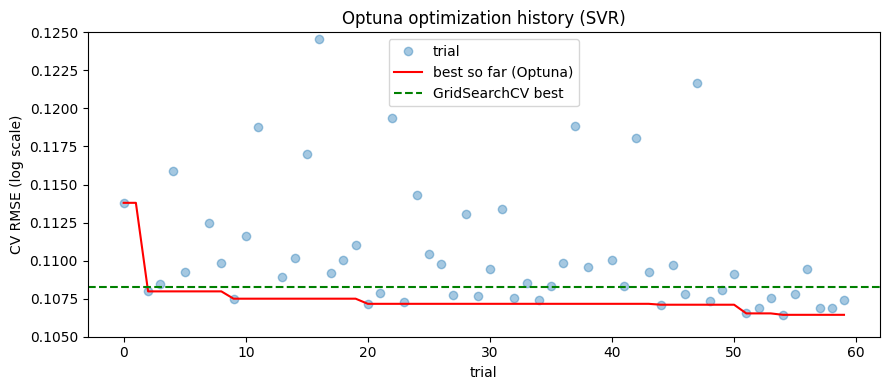

In [ ]:
# 7.3 Optuna (TPE) search for the SVR, compared with GridSearchCV

def objective(trial):
    # Optuna samples CONTINUOUS ranges (not a fixed list of values) and also chooses the numerical transformation
    numeric_transform = trial.suggest_categorical('numeric_transform', ['log1p', 'yeo_johnson'])
    prep = preprocessor_log if numeric_transform == 'log1p' else preprocessor_yj
    model = SVR(kernel='rbf',
                C=trial.suggest_float('C', 1, 1000, log=True),
                gamma=trial.suggest_float('gamma', 1e-5, 1e-2, log=True),
                epsilon=trial.suggest_float('epsilon', 0.005, 0.15))
    pipe = Pipeline([('prep', prep), ('model', model)])
    # same 5-fold CV and same metric as the GridSearchCV, on the training set only
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return -scores.mean()

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=60)
print("Optuna best params:", study.best_params)
print(f"Optuna best CV RMSE (log scale) = {study.best_value:.4f}   (GridSearchCV: {-svr_gs.best_score_:.4f})")

# Refit the best configuration on the training set and evaluate on train / validation only
bp = study.best_params
svr_optuna = Pipeline([('prep', preprocessor_log if bp['numeric_transform'] == 'log1p' else preprocessor_yj),
                       ('model', SVR(kernel='rbf', C=bp['C'], gamma=bp['gamma'], epsilon=bp['epsilon']))])
svr_optuna.fit(X_train, y_train)
display(evaluate_train_val(svr_optuna, 'SVR Optuna (TPE)'))

# Comparison GridSearchCV vs Optuna (same SVR, same CV folds)
rt = results_table()
rows = {'GridSearchCV': ('SVR tuned (log1p)',  -svr_gs.best_score_),
        'Optuna (TPE)':  ('SVR Optuna (TPE)',  study.best_value)}
display(pd.DataFrame({k: {'CV RMSE (log)': cv_rmse,
                          'Val MAE ($)':   rt.loc[(n, 'validation'), 'MAE ($)'],
                          'Val RMSE ($)':  rt.loc[(n, 'validation'), 'RMSE ($)'],
                          'Val R²':        rt.loc[(n, 'validation'), 'R²']}
                      for k, (n, cv_rmse) in rows.items()}).T.round(4))

# Optimization history
trials = study.trials_dataframe()
plt.figure(figsize=(9, 4))
plt.plot(trials['number'], trials['value'], 'o', alpha=0.4, label='trial')
plt.plot(trials['number'], trials['value'].cummin(), color='red', label='best so far (Optuna)')
plt.axhline(-svr_gs.best_score_, color='green', linestyle='--', label='GridSearchCV best')
plt.ylim(0.105, 0.125); plt.xlabel('trial'); plt.ylabel('CV RMSE (log scale)')
plt.title('Optuna optimization history (SVR)'); plt.legend(); plt.tight_layout(); plt.show()

**Note on the Optuna result (extra experiment).** Optuna (TPE, 60 trials) used the same 5-fold CV and the same metric as the GridSearchCV. Its best configuration (Yeo-Johnson transformation, `C` ≈ 55.6, `gamma` ≈ 0.00028, `epsilon` ≈ 0.027) reached a CV RMSE of 0.1064 versus 0.1083 for the GridSearchCV, and a validation R² of 0.944 versus 0.942 (RMSE $17,860 vs $18,085, MAE $12,086 vs $12,732). The improvement is small (about $225 in validation RMSE) and comes from a single validation split. Since the assignment requires GridSearchCV or RandomizedSearchCV, Optuna is treated here as an additional experiment: it is not included in the model comparison of Section 8, and the final model remains the GridSearchCV-tuned SVR. The result does show that a wider continuous search could improve the SVR slightly.

In [ ]:
# 7.4 Model 2 tuning: KNN
knn_grid = {'model__n_neighbors': [3, 5, 7, 9, 11, 15],
            'model__weights': ['uniform', 'distance'],
            'model__p': [1, 2]}                      # 1 = Manhattan, 2 = Euclidean
knn_gs = run_grid(knn_pipeline, knn_grid, 'KNN')
display(evaluate_train_val(knn_gs.best_estimator_, 'KNN tuned (Yeo-Johnson)'))

KNN: best params = {'model__n_neighbors': 5, 'model__p': 1, 'model__weights': 'distance'}
KNN: best CV RMSE (log scale) = 0.1528


MAE ($)           MSE   RMSE ($)     R²  \
Model                   Split                                                   
KNN tuned (Yeo-Johnson) train           0.000  0.000000e+00      0.000  1.000   
                        validation  16719.377  6.669563e+08  25825.496  0.882   

                                    RMSE (log)  R² (log)  
Model                   Split                             
KNN tuned (Yeo-Johnson) train            0.000     1.000  
                        validation       0.148     0.855

In [ ]:
# 7.5 Additional tuning
ridge_gs = run_grid(ridge_pipeline, {'model__alpha': [0.01, 0.1, 1, 3, 10, 30, 100]}, 'Ridge')
lasso_gs = run_grid(lasso_pipeline, {'model__alpha': [0.0001, 0.0003, 0.001, 0.003, 0.01]}, 'Lasso')
display(pd.concat([evaluate_train_val(ridge_gs.best_estimator_, 'Ridge tuned (Yeo-Johnson)'),
                   evaluate_train_val(lasso_gs.best_estimator_, 'Lasso tuned (Yeo-Johnson)')]))

Ridge: best params = {'model__alpha': 10}
Ridge: best CV RMSE (log scale) = 0.1090
Lasso: best params = {'model__alpha': 0.0003}
Lasso: best CV RMSE (log scale) = 0.1084


MAE ($)           MSE   RMSE ($)  \
Model                     Split                                            
Ridge tuned (Yeo-Johnson) train       12136.000  3.471862e+08  18632.933   
                          validation  13457.178  3.835483e+08  19584.390   
Lasso tuned (Yeo-Johnson) train       12108.465  3.465356e+08  18615.466   
                          validation  13475.774  3.738273e+08  19334.614   

                                         R²  RMSE (log)  R² (log)  
Model                     Split                                    
Ridge tuned (Yeo-Johnson) train       0.949       0.093     0.948  
                          validation  0.932       0.118     0.907  
Lasso tuned (Yeo-Johnson) train       0.949       0.092     0.949  
                          validation  0.934       0.116     0.911

In [ ]:
# 7.5 (continued): ElasticNet tuning
elastic_grid = {'model__alpha':    [0.0001, 0.0003, 0.001, 0.003, 0.01],
                'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 1.0]}
elastic_gs = run_grid(elastic_pipeline, elastic_grid, 'ElasticNet')
display(evaluate_train_val(elastic_gs.best_estimator_, 'ElasticNet tuned (Yeo-Johnson)'))

ElasticNet: best params = {'model__alpha': 0.001, 'model__l1_ratio': 0.5}
ElasticNet: best CV RMSE (log scale) = 0.1080


MAE ($)           MSE   RMSE ($)  \
Model                          Split                                            
ElasticNet tuned (Yeo-Johnson) train       12612.004  3.784214e+08  19453.056   
                               validation  13360.319  3.668090e+08  19152.259   

                                              R²  RMSE (log)  R² (log)  
Model                          Split                                    
ElasticNet tuned (Yeo-Johnson) train       0.944       0.095     0.945  
                               validation  0.935       0.115     0.912

#### 📝 Section Summary
All models were tuned with `GridSearchCV` (5-fold CV, `random_state=42`, scoring = RMSE on the log target) using the training set only; the validation set was kept for comparison and the test set was not touched. SVR was tuned over `kernel`, `C`, `gamma`, `epsilon` and `degree` (best: RBF kernel, `C=100`, `gamma=0.0003`, `epsilon=0.05`, CV RMSE = 0.1083): RBF beat the polynomial kernel, small `gamma` values and `epsilon=0.05` (instead of the default 0.1) gave the best results, and `degree=2` was better than 3. KNN was tuned over `n_neighbors`, `weights` and `p` (best: `k=5`, `p=1`, distance weights, CV RMSE = 0.1528); its train R² of 1.0 is an artifact of distance weighting, so the train–validation gap is not informative. Ridge (`alpha=10`, CV RMSE = 0.1090), Lasso (`alpha=0.0003`, 0.1084) and ElasticNet (`alpha=0.001`, `l1_ratio=0.5`, 0.1080) ended up almost identical, with ElasticNet nominally the best. Tuning improved the validation R² of SVR (0.928 → 0.942), KNN (0.861 → 0.882), Ridge (0.930 → 0.932) and Lasso (0.932 → 0.934), while ElasticNet stayed the same (0.935) because its best parameters equal the baseline ones. After tuning, SVR, Ridge, Lasso and ElasticNet are practically tied in CV (≈ 0.108-0.109), with SVR giving the best validation R² (0.942), while KNN remains clearly the weakest (CV RMSE = 0.153, validation R² = 0.882). An additional Optuna search for the SVR reached a slightly lower CV RMSE (0.1064 vs 0.1083) and validation R² (0.944 vs 0.942), but the gain was small and Optuna goes beyond the required GridSearchCV/RandomizedSearchCV, so it was treated as an extra experiment and not used in the final comparison.

## 8. Model Evaluation & Comparison

### 8.1 Metrics on Train / Validation / Test

In [36]:
# 8.1 Metrics on Train / Validation / Test for every model (before and after tuning).
# The test set is used here for the first and only time: models and hyperparameters are already fixed.
final_models = {
    'Baseline (median)':                  baseline,
    'SVR default (log1p)':                svr_pipeline,
    'SVR tuned (log1p)':                  svr_gs.best_estimator_,
    'KNN default (Yeo-Johnson)':          knn_pipeline,
    'KNN tuned (Yeo-Johnson)':            knn_gs.best_estimator_,
    'Ridge default (Yeo-Johnson)':        ridge_pipeline,
    'Ridge tuned (Yeo-Johnson)':          ridge_gs.best_estimator_,
    'Lasso baseline (Yeo-Johnson)':       lasso_pipeline,
    'Lasso tuned (Yeo-Johnson)':          lasso_gs.best_estimator_,
    'ElasticNet baseline (Yeo-Johnson)':  elastic_pipeline,
    'ElasticNet tuned (Yeo-Johnson)':     elastic_gs.best_estimator_,
}

for name, mdl in final_models.items():
    evaluate_train_val(mdl, name)      # refresh train / validation results
    evaluate_test(mdl, name)           # test results (reported only, never used to choose a model)

res = results_table().reset_index()
res = res[res['Model'].isin(final_models)]
for split in ['train', 'validation', 'test']:
    print(f"\n=== {split.upper()} (metrics in dollars) ===")
    display(res[res['Split'] == split].set_index('Model').loc[list(final_models), ['MAE ($)', 'MSE', 'RMSE ($)', 'R²']])


=== TRAIN (metrics in dollars) ===


,MAE ($),MSE,RMSE ($),R²
Model,,,,
Baseline (median),56748.952,7.174940e+09,84705.019,-0.053
SVR default (log1p),12253.176,3.007255e+08,17341.440,0.956
SVR tuned (log1p),9688.338,2.203726e+08,14844.953,0.968
KNN default (Yeo-Johnson),17231.702,7.508390e+08,27401.442,0.890
KNN tuned (Yeo-Johnson),0.000,0.000000e+00,0.000,1.000
Ridge default (Yeo-Johnson),11423.529,3.020870e+08,17380.650,0.956
Ridge tuned (Yeo-Johnson),12136.000,3.471862e+08,18632.933,0.949
Lasso baseline (Yeo-Johnson),13293.208,4.263759e+08,20648.872,0.937
Lasso tuned (Yeo-Johnson),12108.465,3.465356e+08,18615.466,0.949



=== VALIDATION (metrics in dollars) ===


,MAE ($),MSE,RMSE ($),R²
Model,,,,
Baseline (median),53943.123,5.961552e+09,77211.090,-0.055
SVR default (log1p),13268.868,4.046770e+08,20116.585,0.928
SVR tuned (log1p),12732.411,3.270632e+08,18084.889,0.942
KNN default (Yeo-Johnson),17996.066,7.855107e+08,28026.964,0.861
KNN tuned (Yeo-Johnson),16719.377,6.669563e+08,25825.496,0.882
Ridge default (Yeo-Johnson),13893.320,3.974116e+08,19935.186,0.930
Ridge tuned (Yeo-Johnson),13457.178,3.835483e+08,19584.390,0.932
Lasso baseline (Yeo-Johnson),13374.333,3.851649e+08,19625.617,0.932
Lasso tuned (Yeo-Johnson),13475.774,3.738273e+08,19334.614,0.934



=== TEST (metrics in dollars) ===


,MAE ($),MSE,RMSE ($),R²
Model,,,,
Baseline (median),51858.964,4.817060e+09,69405.040,-0.037
SVR default (log1p),13417.261,3.519144e+08,18759.381,0.924
SVR tuned (log1p),11762.913,2.652379e+08,16286.127,0.943
KNN default (Yeo-Johnson),18780.525,7.303883e+08,27025.698,0.843
KNN tuned (Yeo-Johnson),18827.668,7.728184e+08,27799.612,0.834
Ridge default (Yeo-Johnson),13016.268,3.420025e+08,18493.310,0.926
Ridge tuned (Yeo-Johnson),12499.277,3.149499e+08,17746.829,0.932
Lasso baseline (Yeo-Johnson),12739.458,3.414200e+08,18477.555,0.926
Lasso tuned (Yeo-Johnson),12415.344,3.121873e+08,17668.822,0.933


### 8.2 Comparison table

In [37]:
# 8.2 Comparison table: all models in one table (sorted by validation RMSE)
wide = res.pivot(index='Model', columns='Split', values=['MAE ($)', 'RMSE ($)', 'R²'])
wide = wide.reindex(columns=pd.MultiIndex.from_product([['MAE ($)', 'RMSE ($)', 'R²'], ['train', 'validation', 'test']]))
wide[('Gap', 'R² train-val')] = wide[('R²', 'train')] - wide[('R²', 'validation')]
wide[('Gap', 'R² val-test')]  = wide[('R²', 'validation')] - wide[('R²', 'test')]
comparison = wide.sort_values(('RMSE ($)', 'validation')).round(3)
display(comparison)

MAE ($)                         RMSE ($)  \
                                       train validation       test      train   
Model                                                                           
SVR tuned (log1p)                   9688.338  12732.411  11762.913  14844.953   
ElasticNet baseline (Yeo-Johnson)  12612.004  13360.319  12582.008  19453.056   
ElasticNet tuned (Yeo-Johnson)     12612.004  13360.319  12582.008  19453.056   
Lasso tuned (Yeo-Johnson)          12108.465  13475.774  12415.344  18615.466   
Ridge tuned (Yeo-Johnson)          12136.000  13457.178  12499.277  18632.933   
Lasso baseline (Yeo-Johnson)       13293.208  13374.333  12739.458  20648.872   
Ridge default (Yeo-Johnson)        11423.529  13893.320  13016.268  17380.650   
SVR default (log1p)                12253.176  13268.868  13417.261  17341.440   
KNN tuned (Yeo-Johnson)                0.000  16719.377  18827.668      0.000   
KNN default (Yeo-Johnson)          17231.702  17996.066  18780.525  27401.442   
Baseline (median)                  56748.952  53943.123  51858.964  84705.019   

                                                            R²             \
                                  validation       test  train validation   
Model                                                                       
SVR tuned (log1p)                  18084.889  16286.127  0.968      0.942   
ElasticNet baseline (Yeo-Johnson)  19152.259  17878.284  0.944      0.935   
ElasticNet tuned (Yeo-Johnson)     19152.259  17878.284  0.944      0.935   
Lasso tuned (Yeo-Johnson)          19334.614  17668.822  0.949      0.934   
Ridge tuned (Yeo-Johnson)          19584.390  17746.829  0.949      0.932   
Lasso baseline (Yeo-Johnson)       19625.617  18477.555  0.937      0.932   
Ridge default (Yeo-Johnson)        19935.186  18493.310  0.956      0.930   
SVR default (log1p)                20116.585  18759.381  0.956      0.928   
KNN tuned (Yeo-Johnson)            25825.496  27799.612  1.000      0.882   
KNN default (Yeo-Johnson)          28026.964  27025.698  0.890      0.861   
Baseline (median)                  77211.090  69405.040 -0.053     -0.055   

                                                  Gap              
                                    test R² train-val R² val-test  
Model                                                              
SVR tuned (log1p)                  0.943        0.026      -0.001  
ElasticNet baseline (Yeo-Johnson)  0.931        0.009       0.004  
ElasticNet tuned (Yeo-Johnson)     0.931        0.009       0.004  
Lasso tuned (Yeo-Johnson)          0.933        0.015       0.001  
Ridge tuned (Yeo-Johnson)          0.932        0.017       0.000  
Lasso baseline (Yeo-Johnson)       0.926        0.005       0.006  
Ridge default (Yeo-Johnson)        0.926        0.026       0.004  
SVR default (log1p)                0.924        0.028       0.004  
KNN tuned (Yeo-Johnson)            0.834        0.118       0.048  
KNN default (Yeo-Johnson)          0.843        0.029       0.018  
Baseline (median)                 -0.037        0.002      -0.018

### 8.3 Visual comparison

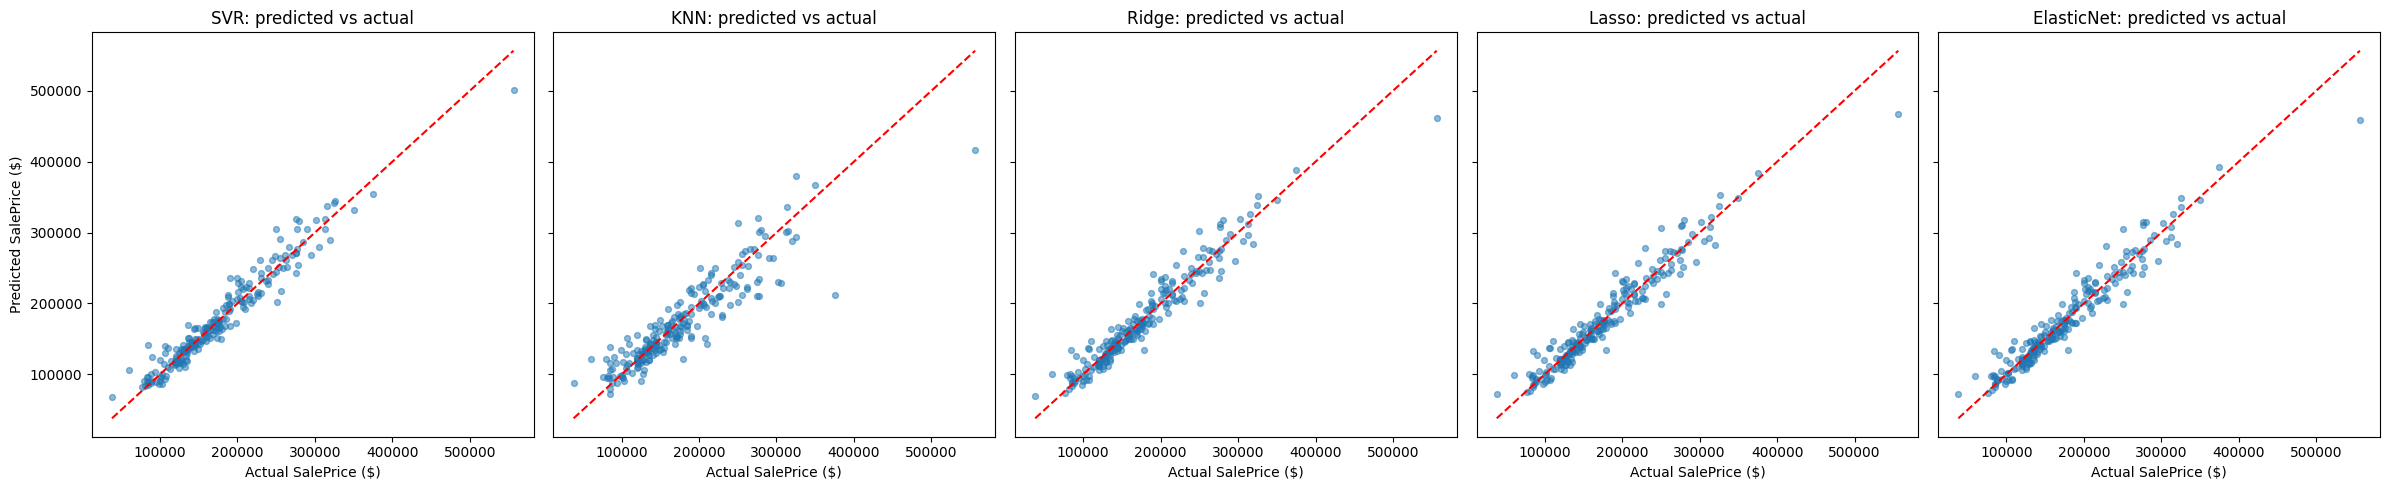

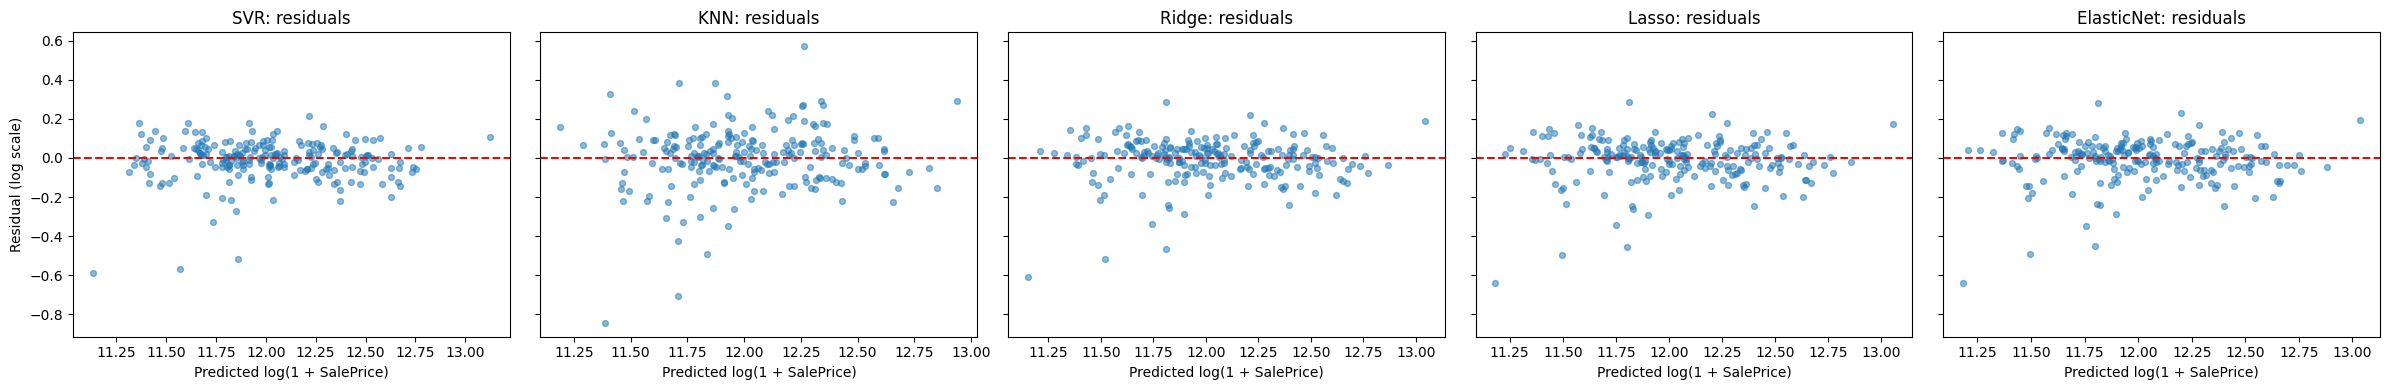

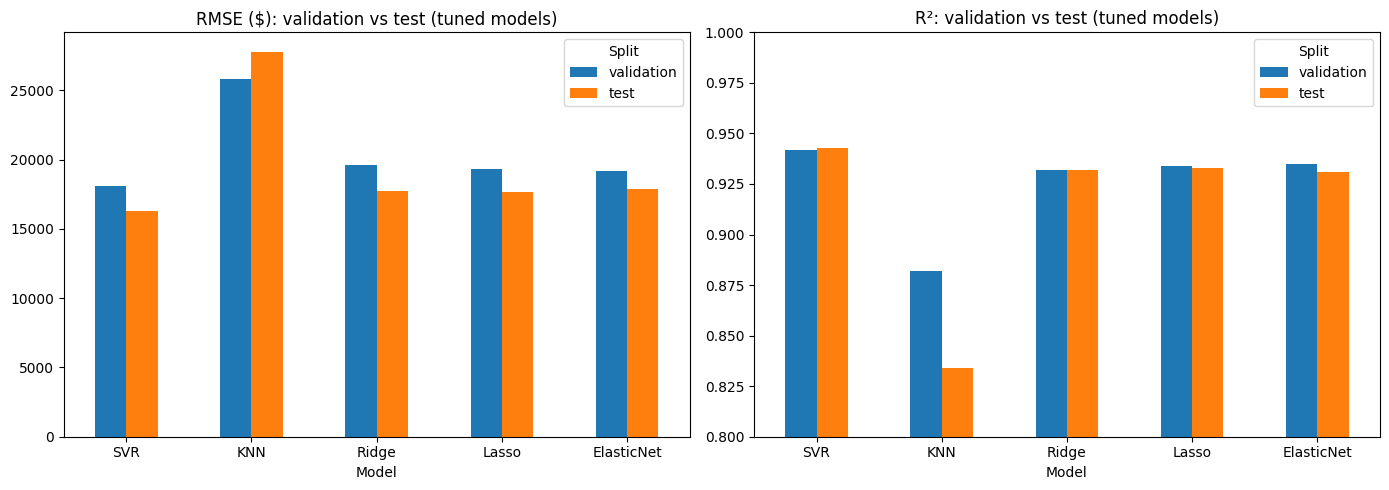

In [38]:
# 8.3 Visual comparison (tuned models, test set)
tuned_models = {'SVR': svr_gs.best_estimator_, 'KNN': knn_gs.best_estimator_, 'Ridge': ridge_gs.best_estimator_,
                'Lasso': lasso_gs.best_estimator_, 'ElasticNet': elastic_gs.best_estimator_}

# (a) Predicted vs actual (dollars)
fig, axes = plt.subplots(1, 5, figsize=(24, 5), sharex=True, sharey=True)
y_true_test = np.expm1(y_test)
for ax, (name, mdl) in zip(axes, tuned_models.items()):
    pred = np.expm1(mdl.predict(X_test))
    ax.scatter(y_true_test, pred, alpha=0.5, s=18)
    lim = [y_true_test.min(), y_true_test.max()]
    ax.plot(lim, lim, color='red', linestyle='--')
    ax.set_title(f'{name}: predicted vs actual'); ax.set_xlabel('Actual SalePrice ($)')
axes[0].set_ylabel('Predicted SalePrice ($)')
plt.tight_layout(); plt.show()

# (b) Residual plots (log scale: residual = log actual - log predicted, so errors are relative)
fig, axes = plt.subplots(1, 5, figsize=(24, 4), sharey=True)
for ax, (name, mdl) in zip(axes, tuned_models.items()):
    pred_log = mdl.predict(X_test)
    ax.scatter(pred_log, y_test - pred_log, alpha=0.5, s=18)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_title(f'{name}: residuals'); ax.set_xlabel('Predicted log(1 + SalePrice)')
axes[0].set_ylabel('Residual (log scale)')
plt.tight_layout(); plt.show()

# (c) Metric comparison barplots (validation vs test)
bars = (res[res['Model'].isin([f'{m} tuned' + (' (log1p)' if m == 'SVR' else ' (Yeo-Johnson)') for m in tuned_models])
            & res['Split'].isin(['validation', 'test'])].copy())
bars['Model'] = bars['Model'].str.replace(r' tuned.*', '', regex=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['RMSE ($)', 'R²']):
    bars.pivot(index='Model', columns='Split', values=metric).loc[list(tuned_models), ['validation', 'test']].plot(kind='bar', ax=ax, rot=0)
    ax.set_title(f'{metric}: validation vs test (tuned models)')
axes[1].set_ylim(0.8, 1.0)
plt.tight_layout(); plt.show()

### 8.4 Discussion

**Best model.** The tuned SVR is the best model on both the validation set (R² = 0.942, RMSE $18.1K, MAE $12.7K) and the test set (R² = 0.943, RMSE $16.3K, MAE $11.8K). The three tuned linear models (ElasticNet, Lasso, Ridge) come next and are practically tied with each other (validation R² 0.932-0.935, test R² 0.931-0.933); the SVR is ahead of them by about 0.007 in validation R² (about $1.1K RMSE) and by 0.010-0.012 in test R² ($1.4K-$1.6K RMSE). The gap is modest, but it appears on both sets. KNN is clearly the weakest model (validation R² = 0.882, test 0.834, RMSE ≈ $26-28K). The median baseline (R² ≈ -0.05) shows that all other models learn real structure.

**Overfitting.** The train–validation R² gap is small for Ridge (0.017), Lasso (0.015) and ElasticNet (0.009), and a little larger for the tuned SVR (0.968 vs 0.942, gap 0.026); but the SVR is also the best on validation and test, so its extra flexibility is not hurting it. The tuned KNN is the exception: with `weights='distance'` each training house is its own nearest neighbour, so the train R² is exactly 1.000 and is not informative; the real evidence is the drop to 0.882 on validation and 0.834 on test, which shows that it generalizes poorly (its validation gain from tuning did not carry over to the test set).

**Underfitting.** The median baseline underfits completely (R² ≈ -0.05). Among the real models, none of the SVR or linear models underfits: train R² is 0.94-0.97 (MAE ≈ $10K-$12.6K) and validation/test R² is almost the same. The default KNN shows signs of relative underfitting: even on the training set it is much worse than the other models (R² = 0.890, MAE ≈ $17.2K, vs 0.956 and $12.3K for the default SVR), which suggests that distance-based neighbours are not informative in this 247-dimensional space (186 sparse one-hot columns). The residual plots show no strong pattern for the SVR and linear models; the largest errors are at the extremes of the price range (very cheap and very expensive houses).

**Train vs validation.** Train and validation metrics are close for the linear models and SVR (train RMSE $14.8K-$19.5K vs validation $18.1K-$19.6K), so these models are not memorizing the training data. For ElasticNet the validation RMSE ($19.2K) is even slightly lower than the train RMSE ($19.5K).

**Did tuning help?** For the SVR, yes, clearly: validation R² 0.928 → 0.942 and test R² 0.924 → 0.943 (test RMSE $18.8K → $16.3K), mainly thanks to a smaller `gamma` and `epsilon`. For the linear models the gain is small but confirmed on the test set: Ridge 0.926 → 0.932 and Lasso 0.926 → 0.933 (validation: 0.930 → 0.932 and 0.932 → 0.934). ElasticNet did not change because its best parameters equal the baseline ones (the two rows are identical). KNN improved on validation (0.861 → 0.882) but **not on test** (0.843 → 0.834), so its tuning gain did not generalize.

**Generalization.** The validation-to-test change in R² is almost zero for the SVR (-0.001, the test score is even slightly higher), Ridge (0.000) and Lasso (0.001), 0.004 for ElasticNet, and large for the tuned KNN (0.048). So the SVR and the linear models generalize well. The test RMSE is about $1.3K-$1.8K lower than the validation RMSE for the SVR and the linear models, which suggests that this test split happens to be slightly easier. The final model is chosen in Section 10 using validation/CV performance, simplicity and interpretability; the test set is used only for confirmation (the SVR is also the best on validation, so the choice does not depend on the test set).

#### 📝 Section Summary
All eleven models (baseline plus default and tuned versions of SVR, KNN, Ridge, Lasso and ElasticNet) were evaluated with MAE, MSE, RMSE and R² (in dollars) on train, validation and test; the test set was used only once, after tuning. The tuned SVR is the best model on both validation (R² = 0.942, RMSE $18.1K) and test (R² = 0.943, RMSE $16.3K), followed by tuned ElasticNet, Lasso and Ridge, which are practically tied (validation R² 0.932-0.935, test R² 0.931-0.933, test RMSE $17.7K-$17.9K), while KNN is clearly weaker (test R² = 0.834). Overfitting is mild for the SVR and linear models (train–validation R² gap ≤ 0.026) and strong for KNN, whose perfect train score is an artifact of distance weighting. Tuning clearly helped the SVR (test R² 0.924 → 0.943) and slightly helped Ridge and Lasso (confirmed on the test set), but not KNN. No model underfits, and the best models make their largest errors on very cheap and very expensive houses.

## 9. Feature Importance & Interpretation

### 9.1 Importance computation
- [ ] Coefficients / feature importance / permutation importance (depending on the model)

ElasticNet alpha = 0.001, l1_ratio = 0.5
Non-zero coefficients: 100 of 247 (ElasticNet set 147 to exactly 0)


,coefficient
MSZoning_C (all),-0.269
TotalSF,0.150
Neighborhood_Crawfor,0.105
OverallQual,0.103
Neighborhood_StoneBr,0.096
Neighborhood_NridgHt,0.067
HouseAge,-0.065
Neighborhood_NoRidge,0.063
GrLivArea,0.062
Exterior1st_BrkFace,0.060


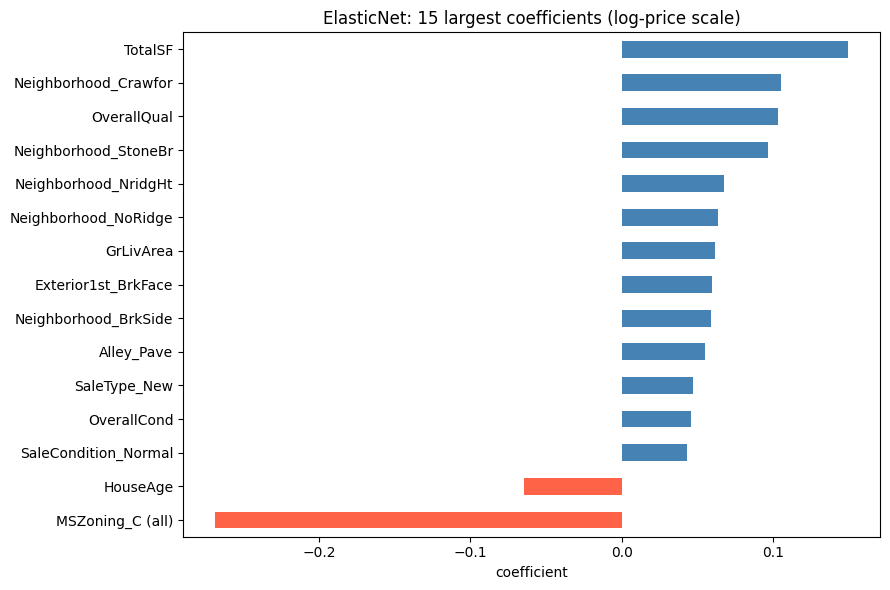

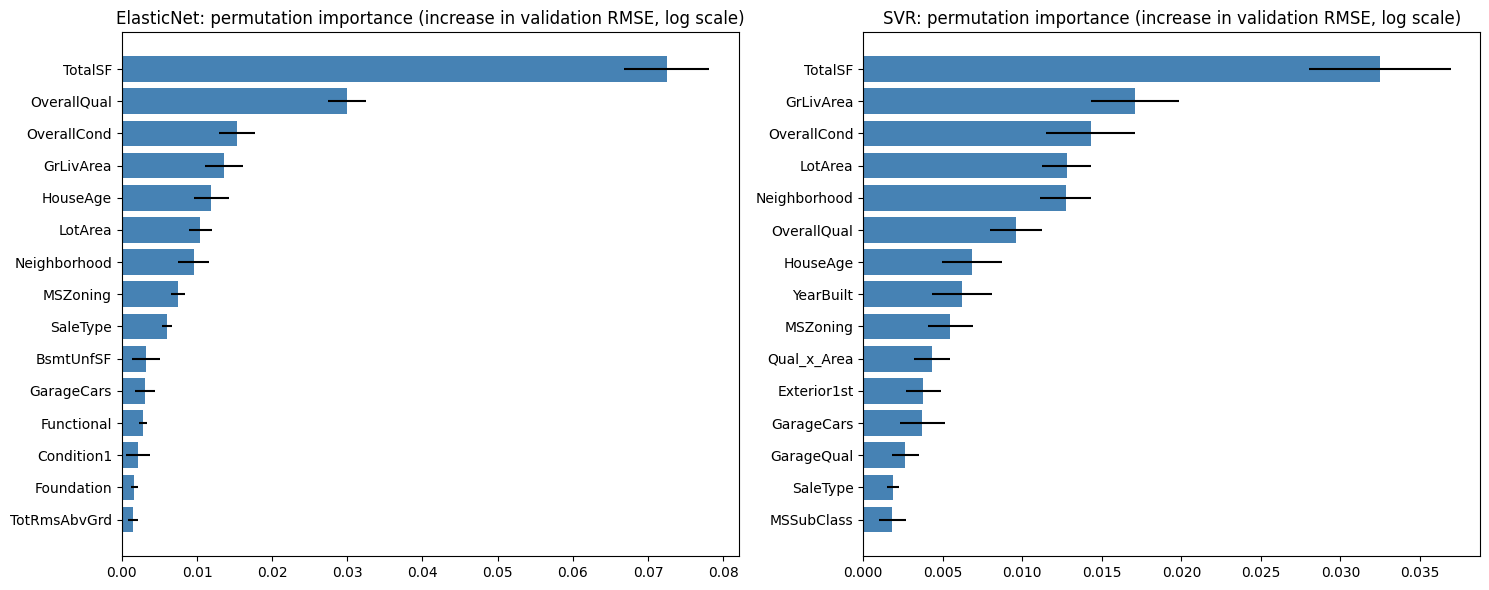

In [39]:
# 9.1a ElasticNet coefficients (the tuned ElasticNet is a linear model, so its coefficients can be read directly)
from sklearn.inspection import permutation_importance

enet_best = elastic_gs.best_estimator_
feat_names = [n.split('__')[-1] for n in enet_best.named_steps['prep'].get_feature_names_out()]
coefs = pd.Series(enet_best.named_steps['model'].coef_, index=feat_names)

print(f"ElasticNet alpha = {enet_best.named_steps['model'].alpha}, l1_ratio = {enet_best.named_steps['model'].l1_ratio}")
print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)} (ElasticNet set {(coefs == 0).sum()} to exactly 0)")

top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
display(top_coefs.round(3).to_frame('coefficient'))

plt.figure(figsize=(9, 6))
top_coefs.sort_values().plot(kind='barh', color=['tomato' if v < 0 else 'steelblue' for v in top_coefs.sort_values()])
plt.title('ElasticNet: 15 largest coefficients (log-price scale)'); plt.xlabel('coefficient')
plt.tight_layout(); plt.show()

# 9.1b Permutation importance (model-agnostic): how much the validation error grows when one ORIGINAL feature is shuffled.
# Computed on the whole pipeline, so every raw column gets one score (no one-hot splitting). Validation set only; test is not used.
def perm_importance(model, name):
    r = permutation_importance(model, X_val, y_val, scoring='neg_root_mean_squared_error',
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    return pd.DataFrame({'importance': r.importances_mean, 'std': r.importances_std}, index=X_val.columns).sort_values('importance', ascending=False)

perm = {'ElasticNet': perm_importance(enet_best, 'ElasticNet'),
        'SVR':        perm_importance(svr_gs.best_estimator_, 'SVR')}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, imp) in zip(axes, perm.items()):
    top = imp.head(15).iloc[::-1]
    ax.barh(top.index, top['importance'], xerr=top['std'], color='steelblue')
    ax.set_title(f'{name}: permutation importance (increase in validation RMSE, log scale)')
plt.tight_layout(); plt.show()

### 9.2 Top features
- [ ] Plot top features
- [ ] Link them to the EDA and insights (Sections 2 and 3)

In [40]:
# 9.2 Top features and agreement between the two models
top10 = pd.DataFrame({'ElasticNet': perm['ElasticNet'].head(10).index, 'SVR': perm['SVR'].head(10).index}, index=range(1, 11))
display(top10)
common = set(perm['ElasticNet'].head(10).index) & set(perm['SVR'].head(10).index)
print(f"{len(common)} of the top-10 features are shared by both models: {sorted(common)}")
display(perm['ElasticNet'].head(10).round(4))
display(perm['SVR'].head(10).round(4))

# Link with the EDA: correlation of the top features with SalePrice (numerical ones)
num_top = [f for f in perm['ElasticNet'].head(10).index if f in num_cols]
display(df_clean[num_top + ['SalePrice']].corr()['SalePrice'].drop('SalePrice').round(2).to_frame('corr with SalePrice'))

,ElasticNet,SVR
1,TotalSF,TotalSF
2,OverallQual,GrLivArea
3,OverallCond,OverallCond
4,GrLivArea,LotArea
5,HouseAge,Neighborhood
6,LotArea,OverallQual
7,Neighborhood,HouseAge
8,MSZoning,YearBuilt
9,SaleType,MSZoning
10,BsmtUnfSF,Qual_x_Area


8 of the top-10 features are shared by both models: ['GrLivArea', 'HouseAge', 'LotArea', 'MSZoning', 'Neighborhood', 'OverallCond', 'OverallQual', 'TotalSF']


,importance,std
TotalSF,0.0725,0.0057
OverallQual,0.0300,0.0026
OverallCond,0.0153,0.0024
GrLivArea,0.0136,0.0026
HouseAge,0.0119,0.0023
LotArea,0.0104,0.0015
Neighborhood,0.0095,0.0020
MSZoning,0.0075,0.0009
SaleType,0.0060,0.0007
BsmtUnfSF,0.0032,0.0019


,importance,std
TotalSF,0.0325,0.0044
GrLivArea,0.0171,0.0028
OverallCond,0.0143,0.0028
LotArea,0.0128,0.0015
Neighborhood,0.0127,0.0016
OverallQual,0.0096,0.0016
HouseAge,0.0068,0.0019
YearBuilt,0.0062,0.0019
MSZoning,0.0055,0.0014
Qual_x_Area,0.0043,0.0011


,corr with SalePrice
TotalSF,0.83
OverallQual,0.80
OverallCond,-0.08
GrLivArea,0.73
HouseAge,-0.52
LotArea,0.27
BsmtUnfSF,0.21


### 9.2 Interpretation

**Method.** Two complementary views were used: (1) the coefficients of the tuned ElasticNet (`alpha = 0.001`, `l1_ratio = 0.5`), which kept 100 of 247 transformed features (147 were set to exactly 0, so the model performed automatic feature selection), and (2) permutation importance computed on the validation set for the tuned ElasticNet and the tuned SVR (increase in RMSE on the log scale when one original feature is shuffled). Since the SVR is the final model (Section 10) and has no coefficients, its permutation importance is the main result, and the ElasticNet coefficients serve as a readable cross-check. Permutation importance is the more reliable ranking, because the raw coefficients mix numerical features (scaled by their IQR) with one-hot columns (not scaled), so their sizes are not directly comparable; the very large coefficient of `MSZoning_C (all)` (-0.27) comes from a category with only a handful of houses.

**Strongest predictors.** For both models the top features are `TotalSF` (total living + basement area), `OverallQual`, `OverallCond`, `GrLivArea`, `HouseAge`, `LotArea` and `Neighborhood`; 8 of the top 10 features are shared by the two models (also `MSZoning`). `TotalSF` is the most important feature of both models; for the ElasticNet, RMSE increases by 0.073 when it is shuffled, more than twice the next one, `OverallQual` (0.030). For the SVR, `TotalSF` is followed by `GrLivArea`, `OverallCond` and `LotArea`.

**Link with the EDA and insights (Sections 2 and 3).**
- *Size and quality* were already the strongest correlates of price in Section 2 (`OverallQual` r = 0.79, `GrLivArea` 0.71); the engineered `TotalSF` has an even higher correlation (0.83), and the models confirm it as the top predictor.
- *Neighborhood* explained about 55% of the price variance in Section 3.2 and is among the top 7 features of both models; several neighborhood dummies (Crawfor, StoneBr, NridgHt, NoRidge) have large positive coefficients.
- *House age* (r = -0.52 in Section 3.4) is among the top 7 features of both models and has a negative coefficient in the ElasticNet: newer houses cost more.
- `OverallCond` is the 3rd most important feature of both models, although its simple correlation with price is almost zero (-0.08). Its effect only appears after controlling for size and quality, so it is a good example of why a model can use information that a single correlation misses.

**Caution.** Correlated features share their importance (`TotalSF`, `GrLivArea`, `TotalBsmtSF` and `Qual_x_Area` measure related things), so each of them looks smaller than the information they carry together. Permutation importance describes what the model uses, not a causal effect of the feature on price.

#### 📝 Section Summary
Feature importance was computed for the tuned ElasticNet (coefficients, with 147 of 247 coefficients set to zero) and, with permutation importance on the validation set, for the tuned ElasticNet and the tuned SVR (the final model). Both models agree on the main drivers of price: total area (`TotalSF`, `GrLivArea`), overall quality and condition, house age, lot area and neighborhood (8 of the top 10 features are shared). These results match the EDA, where quality and size had the highest correlations with price and neighborhood explained about 55% of its variance. Correlated features share importance, and importance does not imply causation.

## 10. Final Model Selection

In [41]:
# 10.1 Selection criteria table: the choice is made with validation / CV / simplicity (NOT with the test set)
candidates = {'SVR':        (svr_gs,     'SVR tuned (log1p)'),
              'KNN':        (knn_gs,     'KNN tuned (Yeo-Johnson)'),
              'Ridge':      (ridge_gs,   'Ridge tuned (Yeo-Johnson)'),
              'Lasso':      (lasso_gs,   'Lasso tuned (Yeo-Johnson)'),
              'ElasticNet': (elastic_gs, 'ElasticNet tuned (Yeo-Johnson)')}

def model_size(est):
    m = est.named_steps['model']
    if hasattr(m, 'coef_'):
        return f"{int((m.coef_ != 0).sum())} of {m.coef_.size} coefficients used"
    if hasattr(m, 'support_'):
        return f"{len(m.support_)} support vectors"
    return f"stores all {len(X_train)} training houses"

res_idx = results_table().reset_index().set_index(['Model', 'Split'])
rows = []
for name, (gs, label) in candidates.items():
    r = res_idx.loc[label]
    rows.append({'Model': name,
                 'CV RMSE (log)':     -gs.best_score_,
                 'Val RMSE ($)':      r.loc['validation', 'RMSE ($)'],
                 'Val R²':            r.loc['validation', 'R²'],
                 'R² gap train-val':  r.loc['train', 'R²'] - r.loc['validation', 'R²'],
                 'Hyperparameters tuned': len(gs.best_params_),
                 'Model size': model_size(gs.best_estimator_)})
selection = pd.DataFrame(rows).set_index('Model').round(4)
display(selection.sort_values('CV RMSE (log)'))

final_name  = 'SVR tuned (log1p)'
final_model = svr_gs.best_estimator_

# Confirmation on the test set (only to confirm, the choice was already made)
display(res_idx.loc[final_name].loc[['train', 'validation', 'test'], ['MAE ($)', 'RMSE ($)', 'R²', 'RMSE (log)', 'R² (log)']])
mae_test = res_idx.loc[(final_name, 'test'), 'MAE ($)']
print(f"Test MAE = ${mae_test:,.0f}, i.e. {mae_test / np.expm1(y_test).median() * 100:.1f}% of the median test price")

,CV RMSE (log),Val RMSE ($),Val R²,R² gap train-val,Hyperparameters tuned,Model size
Model,,,,,,
ElasticNet,0.1080,19152.259,0.935,0.009,2,100 of 247 coefficients used
SVR,0.1083,18084.889,0.942,0.026,4,556 support vectors
Lasso,0.1084,19334.614,0.934,0.015,1,116 of 247 coefficients used
Ridge,0.1090,19584.390,0.932,0.017,1,247 of 247 coefficients used
KNN,0.1528,25825.496,0.882,0.118,3,stores all 1020 training houses


,MAE ($),RMSE ($),R²,RMSE (log),R² (log)
Split,,,,,
train,9688.338,14844.953,0.968,0.078,0.963
validation,12732.411,18084.889,0.942,0.120,0.905
test,11762.913,16286.127,0.943,0.106,0.922


Test MAE = $11,763, i.e. 7.2% of the median test price


### 10.1 Selection criteria and final model

**Recommended model: tuned SVR** (RBF kernel, log1p on skewed features, `C = 100`, `gamma = 0.0003`, `epsilon = 0.05`). The choice was made with the validation and cross-validation results; the test set was used only to confirm it.

**1. Validation / CV performance.** The SVR has the best validation score (RMSE $18,085, R² = 0.942), followed by ElasticNet ($19,152, 0.935), Lasso ($19,335, 0.934) and Ridge ($19,584, 0.932). On the 5-fold CV RMSE (log scale) the four are practically tied (ElasticNet 0.1080, SVR 0.1083, Lasso 0.1084, Ridge 0.1090), so the CV does not separate them and the validation set favors the SVR (about $1.1K, or 6%, lower RMSE). KNN is clearly worse (validation RMSE $25.8K, R² = 0.882, CV RMSE 0.153) and the median baseline has R² ≈ -0.05. On the test set the SVR reaches R² = 0.943 and RMSE = $16.3K, in line with its validation result.

**2. Generalization.** The change from validation to test is negligible (R² 0.942 → 0.943), and the test MAE is $11.8K, about 7.2% of the median test price. KNN does not generalize (R² 0.882 on validation, 0.834 on test).

**3. Overfitting behavior.** The SVR has a larger train–validation R² gap (0.968 vs 0.942 = 0.026) than ElasticNet (0.009), Lasso (0.015) and Ridge (0.017), but it still has the best validation and test scores, so its extra flexibility is not hurting generalization. KNN overfits (gap 0.118; its perfect train score is an artifact of distance weighting).

**4. Appropriate metrics.** RMSE and MAE in dollars are the main criteria because they are in the unit of the problem; RMSE penalizes large errors, MAE shows the typical error. R² is used to compare with the baseline. The target was modelled on the log scale, so the log-scale RMSE (≈ 0.12) and the CV RMSE on the log scale were also checked: they measure relative error, which is appropriate because expensive houses have larger absolute errors. MSE is reported but not used for the decision (it is in squared dollars and hard to interpret).

**5. Model complexity and interpretability.** The SVR is a non-linear model with four tuned hyperparameters (`kernel`, `C`, `gamma`, `epsilon`) and 556 support vectors (about 55% of the 1,020 training houses). It has no coefficients, so it was interpreted with permutation importance (Section 9). ElasticNet is simpler: it uses only 100 of 247 coefficients and two hyperparameters, and its coefficients can be read directly.

**6. Why SVR over the alternatives.**
- *ElasticNet* has the best CV RMSE by a very small margin (0.1080 vs 0.1083), the smallest overfitting gap and is easier to interpret, but its validation RMSE is about $1.1K higher. It is the best alternative if interpretability matters more than accuracy.
- *Lasso* and *Ridge* are very close to ElasticNet and slightly worse in CV and validation; Ridge keeps all 247 features.
- *KNN* is clearly the weakest and overfits.
- *SVR tuned with Optuna* (Section 7.3, extra experiment) reached a slightly better CV RMSE (0.1064 vs 0.1083) and validation R² (0.944 vs 0.942, RMSE $17,860 vs $18,085). The gain is small (about $225 in RMSE), comes from a single validation split, and the method goes beyond what the assignment requires (GridSearchCV or RandomizedSearchCV), so it was not used in the final comparison. The recommended model is therefore the GridSearchCV-tuned SVR.
- The differences between the SVR and the linear models are modest (about 0.007 in validation R²), so the SVR is a justified rather than a dramatic winner; the main reasons are its best validation accuracy, a CV score equal to the best one, and a test result that confirms it.

#### 📝 Section Summary
The final recommended model is the tuned SVR (RBF kernel, `C = 100`, `gamma = 0.0003`, `epsilon = 0.05`). It had the best validation score (R² = 0.942, RMSE ≈ $18.1K), a CV RMSE practically equal to the best one (0.1083 vs 0.1080 for ElasticNet), and the test set confirmed the choice (R² = 0.943, RMSE ≈ $16.3K, MAE ≈ 7.2% of the median price). The tuned ElasticNet, Lasso and Ridge were close (validation R² 0.932-0.935) and ElasticNet remains the simpler, more interpretable alternative (100 of 247 coefficients, smallest train–validation gap). KNN was rejected for its weaker performance and poor generalization, and the baseline confirmed that all other models learn real structure.

# PART D: Reproducibility & Conclusions

## 11. Reproducibility & Conclusions

### 11.1 Reproducibility checklist

- [x] **`random_state` set everywhere.** One constant, `RANDOM_STATE = 42`, is used for `df.sample`, both `train_test_split` calls (stratified by price bins), the `KFold` used by every `GridSearchCV` (`shuffle=True`) and `permutation_importance`. SVR, KNN, Ridge, Lasso and ElasticNet (default settings) are deterministic, so they need no seed.
- [x] **No data leakage.**
  - The outlier removal, the `'None'` fill for absent features and the 8 engineered features are rule-based, row-wise operations (nothing is learned from the data), so doing them before the split is safe (Section 4.2).
  - The data was split into train / validation / test before anything was fitted.
  - Imputers, power transforms, scalers and encoders are inside the `Pipeline` / `ColumnTransformer`, so they are fitted on the training data only (inside cross-validation, on the training folds only). The list of skewed features was also found on the training set.
  - Hyperparameters were tuned with 5-fold CV on the training set, models were compared on the validation set, and the test set was used only for the final reporting (Section 8.1); no choice was made from it.
- [x] **Notebook runs top to bottom (Restart & Run All).** Tick this box after a final *Restart & Run All* with no errors. `train.csv` must be in the same folder as the notebook (on Colab, upload it first).
- [x] **`requirements.txt` matches the imports.** The cell below reads the installed versions of the five third-party libraries imported in this notebook (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`; `os` is part of Python) and writes them to `requirements.txt`.

In [50]:
# 11.1 Reproducibility check: environment, split integrity, deterministic refit and requirements.txt
import platform
from importlib import metadata

print("=== REPRODUCIBILITY SUMMARY ===")
print(f"Python version : {platform.python_version()}")
print(f"RANDOM_STATE   : {RANDOM_STATE}")
print(f"Split sizes    : train = {len(X_train)}, validation = {len(X_val)}, test = {len(X_test)}")

# 1) Split integrity: every house is in exactly one set
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(X)
print("Split check    : OK (no house appears in more than one set)")

# 2) Refitting the final pipeline from scratch gives the same predictions
refit_model = clone(final_model).fit(X_train, y_train)
same_predictions = np.allclose(refit_model.predict(X_val), final_model.predict(X_val))
print(f"Refit check    : {'OK' if same_predictions else 'FAILED'} (refitted final model gives identical validation predictions)")

# 3) requirements.txt built from the third-party libraries imported in this notebook
packages = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'optuna']
requirements = [f"{p}=={metadata.version(p)}" for p in packages]
with open('requirements.txt', 'w') as f:
    f.write("\n".join(requirements) + "\n")
print("\nrequirements.txt written:")
print("\n".join(requirements))

=== REPRODUCIBILITY SUMMARY ===
Python version : 3.10.0
RANDOM_STATE   : 42
Split sizes    : train = 1020, validation = 219, test = 219
Split check    : OK (no house appears in more than one set)
Refit check    : OK (refitted final model gives identical validation predictions)

requirements.txt written:
pandas==2.3.3
numpy==1.24.4
matplotlib==3.10.8
seaborn==0.13.2
scikit-learn==1.3.2
optuna==5.0.0


### 11.2 Main conclusions

**Key findings**
- **Data and preprocessing.** The Ames training set has 1,460 houses and 81 columns. `SalePrice` is right-skewed (skew 1.88), so the models were trained on `log1p(SalePrice)` and the metrics are reported in dollars. Two outlier houses (Id 524 and 1299) were removed and 8 features were engineered (for example `TotalSF`, `TotalBath`, `HouseAge`). All preprocessing is done in three pipelines (numerical, nominal, ordinal) combined with a `ColumnTransformer` that outputs 247 features.
- **What drives price.** Size dominates and quality matters. `TotalSF` is the most important feature of both final candidates, followed by `OverallCond`, `GrLivArea`, `OverallQual`, `HouseAge`, `LotArea` and `Neighborhood` (the exact order differs between the SVR and the ElasticNet, which ranks `OverallQual` second).
- **Model performance.** Five models (SVR, KNN, Ridge, Lasso, ElasticNet) were trained and tuned, and all of them clearly beat the median baseline (R² ≈ -0.05). The tuned SVR is the best: validation R² = 0.942 (RMSE $18.1K) and test R² = 0.943 (RMSE $16.3K, MAE $11.8K, about 7.2% of the median test price). The tuned linear models are close behind (validation R² 0.932-0.935) and KNN is the weakest (test R² = 0.834). Tuning clearly helped the SVR (test R² 0.924 → 0.943). An extra Optuna search for the SVR gave a slightly better CV RMSE (0.1064 vs 0.1083) and validation R² (0.944 vs 0.942), but the gain was small and it was not used in the final comparison.
- **Generalization.** The train–validation R² gap is at most 0.026 for the SVR and the linear models, none of them underfits, and the SVR scores the same on validation and test. KNN is the only model that overfits and does not generalize.
- **Final recommendation.** The tuned SVR (RBF kernel, `C = 100`, `gamma = 0.0003`, `epsilon = 0.05`), tuned with GridSearchCV. The tuned ElasticNet is the simpler alternative (100 of 247 coefficients) if interpretability matters more than accuracy.

**Limitations**
- The advantage of the SVR over the linear models is modest (about 0.007 in validation R², and the CV RMSE is practically tied), and it comes from a single train / validation / test split. The test set has only 219 houses, and its RMSE is $1.3K-$1.8K lower than the validation RMSE, so this split seems slightly easier.
- The largest errors are on very cheap and very expensive houses.
- The SVR has no coefficients, so it was interpreted with permutation importance, which splits importance between correlated features (`TotalSF`, `GrLivArea`, `TotalBsmtSF`) and does not show causation.
- The data covers one city (Ames, Iowa) and sales from 2006 to 2010 only, so the results may not transfer to other markets or periods. The hyperparameter grids were limited, and the two removed outliers were chosen by judgment.

**Possible improvements** (not tested in this project)
- Try tree-based ensembles (Random Forest, Gradient Boosting, XGBoost), which can capture interactions without hand-made features.
- Use repeated or nested cross-validation to check that the SVR advantage over ElasticNet is real.
- Study the houses with the largest errors (the cheapest and the most expensive) and add features or a separate model for them.
- Run a longer or wider continuous search (the Optuna experiment in Section 7.3 already suggests a small gain) and compare the best configuration on repeated CV before using it as the final model.
- Retrain the final model on train + validation data before using it on new houses.

#### 📝 Section Summary
The notebook was designed to be reproducible: one `RANDOM_STATE = 42` is used for the splits, the cross-validation and the permutation importance, all fitted preprocessing is inside the pipelines (fitted on the training data only), and the test set was used only for final reporting. A check cell confirms that the three sets do not overlap, that refitting the final pipeline gives identical predictions, and writes `requirements.txt` from the installed library versions. The final recommended model is the tuned SVR (test R² = 0.943, RMSE ≈ $16.3K, MAE ≈ 7.2% of the median price), driven mainly by total area, quality, condition, house age, lot area and neighborhood. Its advantage over the linear models is modest, and the main limits are one dataset from one city and one data split.